# Sleep prediction: exploratory data analysis

In the first iteration I took the inputs from earlier research and went straight to modelling. In this notebook I first explore the data step by step: what it contains, where values are missing, how each feature is distributed, which values look wrong, and how the features relate to the following night's sleep. Choosing the features comes after this exploration, as a separate step.

### Contents
- **Prepare the table:** load and clean the data, and keep the test nights out.
- **Step 1: First look at unseen data:** what each row and column holds.
- **Step 2: Missing values:** where values are missing, and whether those nights sleep differently.
- **Step 3: Numerical features:** how each measurement and score is spread, and the target itself.
- **Step 4: Categorical features:** weekdays, last activity and the yes/no answers.
- **Step 5: Outliers:** unusual values, and the rule for nights under 3 hours.
- **Step 6: Relationship with the target:** which features go together with the following night's sleep.
- **Conclusion:** the features carried into feature selection, and the ones dropped.

## Setup

In [1]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans

# One seed for everything random, so the results are the same every run.
SEED = 0

DATA_DIR = Path("../data/raw/pmdata")
participant_folders = sorted(DATA_DIR.glob("p[0-9][0-9]"))
if not participant_folders:
    raise FileNotFoundError(f"No participant folders found in {DATA_DIR.resolve()}")

## Prepare the table
These cells repeat the cleaning from the first notebook, where each decision is explained, so this notebook starts from the same 1,745 nights. Every row is one participant's day, from waking up to 21:00, and the sleep that followed. On top of the first notebook's inputs, they also add everything else PMData records before 21:00: details of the previous night, calories, the training log, and the extra morning-report and daily-report answers.

In [2]:
sleep_columns = {
    "logId": "sleep_id",
    "dateOfSleep": "sleep_date",
    "startTime": "start_time",
    "endTime": "end_time",
    "minutesAsleep": "minutes_asleep",
}

sleep_tables = []
for folder in participant_folders:
    records = pd.read_json(folder / "fitbit/sleep.json", convert_dates=False)
    main_sleep = records.loc[records["mainSleep"].eq(True), list(sleep_columns)].copy()
    main_sleep["participant_id"] = folder.name
    sleep_tables.append(main_sleep)

sleep = pd.concat(sleep_tables, ignore_index=True).rename(columns=sleep_columns)
for column in ["sleep_date", "start_time", "end_time"]:
    sleep[column] = pd.to_datetime(sleep[column], errors="coerce", format="mixed")
sleep["minutes_asleep"] = pd.to_numeric(sleep["minutes_asleep"], errors="coerce")

# Remove exact duplicates, then average each night with the two calendar nights before it.
sleep_clean = sleep.drop_duplicates(ignore_index=True)
sleep_clean = sleep_clean.sort_values(["participant_id", "sleep_date"]).reset_index(drop=True)
sleep_clean["avg_sleep_last_3_nights"] = (
    sleep_clean.groupby("participant_id")
    .rolling("3D", on="sleep_date")["minutes_asleep"]
    .mean()
    .to_numpy()
)

# The activity window runs from the recorded wake-up time to 21:00.
prediction_days = sleep_clean[["participant_id", "sleep_date", "end_time"]].rename(columns={
    "sleep_date": "date",
    "end_time": "wake_up_time",
})
prediction_days["prediction_time"] = prediction_days["date"] + pd.Timedelta(hours=21)
prediction_days = prediction_days.loc[
    prediction_days["wake_up_time"].notna()
    & (prediction_days["wake_up_time"] < prediction_days["prediction_time"])
].copy()

In [3]:
exercise_tables = []
for folder in participant_folders:
    records = pd.read_json(folder / "fitbit/exercise.json", convert_dates=False)
    records["participant_id"] = folder.name
    exercise_tables.append(records)
exercise_records = pd.concat(exercise_tables, ignore_index=True)

# Expand the activity breakdown into separate columns.
levels = pd.json_normalize(
    exercise_records.to_dict("records"),
    record_path="activityLevel",
    meta=["participant_id", "logId", "activityName", "startTime", "duration"]
).drop_duplicates()
exercise_sessions = levels.pivot(
    index=["participant_id", "logId", "activityName", "startTime", "duration"],
    columns="name",
    values="minutes"
).reset_index()
exercise_sessions.columns.name = None
exercise_sessions = exercise_sessions.rename(columns={
    "logId": "session_id",
    "activityName": "activity_type",
    "startTime": "start_time",
    "lightly": "lightly_active_minutes",
    "fairly": "moderately_active_minutes",
    "very": "very_active_minutes"
})
exercise_sessions["start_time"] = pd.to_datetime(exercise_sessions["start_time"])
duration_ms = pd.to_numeric(exercise_sessions["duration"])
exercise_sessions["end_time"] = exercise_sessions["start_time"] + pd.to_timedelta(duration_ms, unit="ms")

# Minute-level steps taken between waking up and 21:00.
step_tables = []
for folder in participant_folders:
    records = pd.read_json(folder / "fitbit/steps.json", convert_dates=False)
    records["participant_id"] = folder.name
    step_tables.append(records.drop_duplicates())
all_steps = pd.concat(step_tables, ignore_index=True)
all_steps["dateTime"] = pd.to_datetime(all_steps["dateTime"])
all_steps["date"] = all_steps["dateTime"].dt.normalize()

steps_in_window = all_steps.merge(prediction_days, on=["participant_id", "date"])
steps_in_window = steps_in_window.loc[
    (steps_in_window["dateTime"] >= steps_in_window["wake_up_time"])
    & (steps_in_window["dateTime"] < steps_in_window["prediction_time"])
]
window_steps = (
    steps_in_window.groupby(["participant_id", "date"])["value"]
    .sum().rename("steps").reset_index()
)

# Sessions that started after waking up and ended by 21:00.
sessions = exercise_sessions.assign(date=exercise_sessions["start_time"].dt.normalize())
sessions = sessions.merge(prediction_days, on=["participant_id", "date"])
sessions = sessions.loc[
    (sessions["start_time"] >= sessions["wake_up_time"])
    & (sessions["end_time"] <= sessions["prediction_time"])
]
minute_columns = ["lightly_active_minutes", "moderately_active_minutes", "very_active_minutes"]
window_sessions = (
    sessions.groupby(["participant_id", "date"])
    .agg(session_count=("session_id", "size"), **{c: (c, "sum") for c in minute_columns})
    .reset_index()
)

last_session = sessions.sort_values("end_time").groupby(["participant_id", "date"]).tail(1)
last_session = last_session.assign(
    min_since_last_activity=(
        last_session["prediction_time"] - last_session["end_time"]
    ).dt.total_seconds() / 60
)[["participant_id", "date", "activity_type", "min_since_last_activity"]]
last_session = last_session.rename(columns={"activity_type": "last_activity"})

daily_activity = prediction_days
for table in [window_steps, window_sessions, last_session]:
    daily_activity = daily_activity.merge(
        table, on=["participant_id", "date"], how="left", validate="one_to_one"
    )
session_columns = ["session_count"] + minute_columns
daily_activity[session_columns] = daily_activity[session_columns].fillna(0).astype(int)
daily_activity["last_activity"] = daily_activity["last_activity"].fillna("None")

In [4]:
previous_sleep = sleep_clean.rename(columns={
    "sleep_date": "date",
    "start_time": "previous_bedtime",
    "minutes_asleep": "previous_sleep_minutes",
}).drop(columns=["sleep_id", "end_time"])

following_sleep = sleep_clean.rename(columns={
    "sleep_date": "date",
    "minutes_asleep": "next_sleep_minutes",
})[["participant_id", "date", "next_sleep_minutes"]]
# Match sleep ending on Wednesday to Tuesday's activity.
following_sleep["date"] = following_sleep["date"] - pd.Timedelta(days=1)

combined_data = (
    daily_activity
    .merge(previous_sleep, on=["participant_id", "date"], how="left", validate="one_to_one")
    .merge(following_sleep, on=["participant_id", "date"], how="left", validate="one_to_one")
)

combined_data = combined_data.loc[combined_data["participant_id"] != "p12"]
combined_data = combined_data.dropna(subset=["next_sleep_minutes"])
combined_data = combined_data.loc[combined_data["steps"].notna()].reset_index(drop=True)

def clock_hours(times):
    """Hours from midnight, with evening times (18:00 or later) counted as negative."""
    hours = times.dt.hour + times.dt.minute / 60
    return hours.where(hours < 18, hours - 24)

# Find the same short-night groups as the first notebook and remove group 3.
nights = sleep_clean.assign(
    date=sleep_clean["sleep_date"] - pd.Timedelta(days=1),
    start_hour=clock_hours(sleep_clean["start_time"]),
    end_hour=clock_hours(sleep_clean["end_time"]),
)
nights["end_hour"] = nights["end_hour"].where(nights["end_hour"] >= nights["start_hour"], nights["end_hour"] + 24)
short_nights = (
    combined_data.loc[
        combined_data["next_sleep_minutes"].between(60, 240),
        ["participant_id", "date", "next_sleep_minutes"]
    ]
    .merge(nights[["participant_id", "date", "start_hour", "end_hour"]], on=["participant_id", "date"])
)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=SEED)
short_nights["group"] = kmeans.fit_predict(short_nights[["start_hour", "end_hour"]])
group_order = short_nights.groupby("group")["start_hour"].median().sort_values().index
short_nights["group"] = short_nights["group"].map({group: number for number, group in enumerate(group_order, start=1)})
group_3_keys = short_nights.loc[short_nights["group"] == 3].set_index(["participant_id", "date"]).index
combined_keys = combined_data.set_index(["participant_id", "date"]).index
combined_data = combined_data.loc[~combined_keys.isin(group_3_keys)].reset_index(drop=True)

In [5]:
candidates = combined_data[["participant_id", "date"]].copy()

wake_up = combined_data["wake_up_time"]
candidates["wake_up_hour"] = wake_up.dt.hour + wake_up.dt.minute / 60
bedtime = combined_data["previous_bedtime"]
bedtime_hour = bedtime.dt.hour + bedtime.dt.minute / 60
candidates["previous_bedtime_hour"] = bedtime_hour.where(bedtime_hour < 12, bedtime_hour - 24)

ready_columns = [
    "previous_sleep_minutes", "avg_sleep_last_3_nights", "steps", "session_count",
    *minute_columns, "last_activity", "min_since_last_activity", "next_sleep_minutes",
]
candidates[ready_columns] = combined_data[ready_columns]

# On days without a session, count the whole time from wake-up to 21:00.
minutes_awake = (combined_data["prediction_time"] - combined_data["wake_up_time"]).dt.total_seconds() / 60
candidates["min_since_last_activity"] = candidates["min_since_last_activity"].fillna(minutes_awake)

candidates["weekday"] = candidates["date"].dt.day_name()
candidates["weekend_night"] = candidates["date"].dt.dayofweek.isin([4, 5]).astype(int)

In [6]:
wellness_features = ["stress", "fatigue", "mood", "sleep_quality"]

wellness_tables = []
for folder in participant_folders:
    records = pd.read_csv(folder / "pmsys/wellness.csv")
    records["participant_id"] = folder.name
    wellness_tables.append(records)
wellness = pd.concat(wellness_tables, ignore_index=True)
wellness["reported_at"] = pd.to_datetime(wellness["effective_time_frame"], utc=True, errors="coerce")

wellness_clean = wellness.copy()
wellness_clean["date"] = wellness_clean["reported_at"].dt.tz_localize(None).dt.normalize()
for participant, date in [("p03", "2020-02-02"), ("p13", "2019-12-21")]:
    reports = wellness_clean.loc[
        wellness_clean["participant_id"].eq(participant)
        & wellness_clean["date"].eq(pd.Timestamp(date))
    ]
    wellness_clean.loc[reports["reported_at"].idxmin(), "date"] -= pd.Timedelta(days=1)

valid_wellness_scores = (
    wellness_clean[wellness_features].ge(1) & wellness_clean[wellness_features].le(5)
).all(axis=1)
wellness_clean = (
    wellness_clean.loc[valid_wellness_scores]
    .sort_values(["participant_id", "date", "reported_at"])
    .drop_duplicates(["participant_id", "date"], keep="first")
)
wellness_inputs = wellness_clean.set_index(["participant_id", "date"])[wellness_features].rename(
    columns={"sleep_quality": "previous_sleep_quality"}
)

candidates = candidates.join(wellness_inputs, on=["participant_id", "date"], validate="one_to_one")
wellness_nights = candidates[["participant_id", "date"]].loc[candidates["stress"].notna()]

In [7]:
nutrition_tables = []
for folder in participant_folders:
    report_file = folder / "googledocs/reporting.csv"
    if report_file.is_file():
        records = pd.read_csv(report_file)
        records["participant_id"] = folder.name
        nutrition_tables.append(records)

nutrition_reports = pd.concat(nutrition_tables, ignore_index=True)
nutrition_reports["report_date"] = pd.to_datetime(nutrition_reports["date"], format="%d/%m/%Y", errors="coerce")
nutrition_reports["submitted_at"] = pd.to_datetime(
    nutrition_reports["timestamp"], format="%d/%m/%Y %H:%M:%S", errors="coerce"
)
nutrition_answer_columns = [
    "participant_id", "date", "meals", "weight", "glasses_of_fluid", "alcohol_consumed"
]
nutrition_day_keys = ["participant_id", "report_date"]

# Only the reports that describe a night with a wellness report.
nutrition_diagnostics = nutrition_reports.merge(
    wellness_nights.rename(columns={"date": "report_date"}),
    on=nutrition_day_keys, how="inner", validate="many_to_one",
)
nutrition_diagnostics["gap_days"] = (
    nutrition_diagnostics["submitted_at"].dt.normalize() - nutrition_diagnostics["report_date"]
).dt.days

# Remove identical copies, keeping the earliest one submitted on or after its date.
nutrition_diagnostics["valid_date_order"] = nutrition_diagnostics["gap_days"].ge(0)
nutrition_deduplicated = (
    nutrition_diagnostics.sort_values(["valid_date_order", "submitted_at"], ascending=[False, True], kind="stable")
    .drop_duplicates(nutrition_answer_columns, keep="first")
    .sort_values(["participant_id", "report_date", "submitted_at"])
    .copy()
)

# Reports submitted before their date: move them when the proposed date is free, otherwise remove them.
early_nutrition_reports = nutrition_deduplicated.loc[nutrition_deduplicated["gap_days"].lt(0)]
date_comparison = early_nutrition_reports[["participant_id", "report_date", "submitted_at", "gap_days"]].copy()
date_comparison["proposed_date"] = date_comparison["report_date"] - pd.DateOffset(months=1)
one_day_early = date_comparison["gap_days"].eq(-1)
date_comparison.loc[one_day_early, "proposed_date"] = date_comparison.loc[one_day_early, "submitted_at"].dt.normalize()

reported_dates = set(zip(nutrition_reports["participant_id"], nutrition_reports["report_date"]))
iteration_2_dates = set(zip(wellness_nights["participant_id"], wellness_nights["date"]))
move_report = pd.Series([
    (person, day) not in reported_dates and (person, day) in iteration_2_dates
    for person, day in zip(date_comparison["participant_id"], date_comparison["proposed_date"])
], index=date_comparison.index)

nutrition_clean = nutrition_deduplicated.copy()
nutrition_clean.loc[date_comparison.index[move_report], "report_date"] = date_comparison.loc[move_report, "proposed_date"]
nutrition_clean = nutrition_clean.drop(index=date_comparison.index[~move_report])

# p14, 17–20 November: separate meal reports, added up into one report per day.
p14_meal_days = nutrition_clean["participant_id"].eq("p14") & nutrition_clean["report_date"].between(
    "2019-11-17", "2019-11-20"
)
p14_meal_reports = nutrition_clean.loc[p14_meal_days].sort_values("submitted_at").copy()
p14_meal_reports["meals"] = p14_meal_reports.groupby(nutrition_day_keys)["meals"].transform(", ".join)
p14_meal_reports["glasses_of_fluid"] = p14_meal_reports.groupby(nutrition_day_keys)["glasses_of_fluid"].transform("sum")
nutrition_clean = pd.concat([
    nutrition_clean.loc[~p14_meal_days],
    p14_meal_reports.drop_duplicates(nutrition_day_keys, keep="last"),
]).sort_values(["participant_id", "report_date", "submitted_at"])

# Other same-day pairs: the earlier submission describes the previous day.
nutrition_multiple_reports = nutrition_clean.loc[nutrition_clean.duplicated(nutrition_day_keys, keep=False)]
same_day_reports = nutrition_multiple_reports.groupby(nutrition_day_keys).filter(
    lambda reports: reports["submitted_at"].dt.normalize().nunique() == 1
)
reports_to_move = same_day_reports.groupby(nutrition_day_keys).head(1)
nutrition_clean.loc[reports_to_move.index, "report_date"] = reports_to_move["report_date"] - pd.Timedelta(days=1)
nutrition_clean = nutrition_clean.sort_values(["participant_id", "report_date", "submitted_at"])

# Remaining conflicts: keep the first report, the next-day correction, or move a month-late report.
conflicting_reports = nutrition_clean.loc[nutrition_clean.duplicated(nutrition_day_keys, keep=False)]
first_report_nights = {
    ("p13", "2019-11-22"), ("p13", "2019-11-23"),
    ("p05", "2020-02-03"), ("p06", "2019-12-13"),
    ("p06", "2020-02-02"), ("p08", "2019-12-22"),
    ("p10", "2020-01-16"), ("p04", "2020-02-29"),
}
selected_reports = []
for (person, day), reports in conflicting_reports.groupby(nutrition_day_keys):
    if (person, day.strftime("%Y-%m-%d")) in first_report_nights:
        selected = reports.head(1).copy()
    elif reports["submitted_at"].iloc[1].normalize() == day + pd.Timedelta(days=1):
        selected = reports.tail(1).copy()
    else:
        selected = reports.copy()
        selected.loc[reports.index[1], "report_date"] = day + pd.DateOffset(months=1)
    selected_reports.append(selected[nutrition_clean.columns])
nutrition_clean = pd.concat([
    nutrition_clean.loc[~nutrition_clean.index.isin(conflicting_reports.index)],
    *selected_reports,
]).sort_values(["participant_id", "report_date", "submitted_at"])

nutrition_keys = pd.MultiIndex.from_frame(nutrition_clean[nutrition_day_keys])
wellness_keys = pd.MultiIndex.from_frame(wellness_nights)

nutrition_inputs = nutrition_clean.drop(columns="date").rename(columns={"report_date": "date"}).set_index(["participant_id", "date"])
meal_lists = nutrition_inputs["meals"].str.split(", ")
nutrition_inputs = pd.DataFrame({
    "meal_count": meal_lists.apply(lambda meals: len(set(meals))),
    "had_breakfast": meal_lists.apply(lambda meals: "Breakfast" in meals).astype(int),
    # "Evening" is the Norwegian evening meal (kveldsmat), a separate, later meal than "Dinner" (middag).
    "had_evening_meal": meal_lists.apply(lambda meals: "Evening" in meals).astype(int),
    "glasses_of_fluid": nutrition_inputs["glasses_of_fluid"],
    "drank_alcohol": nutrition_inputs["alcohol_consumed"].map({"Yes": 1, "No": 0}),
})

# Nutrition was cleaned for the wellness nights only, so it is matched to those nights.
has_wellness = candidates["stress"].notna()
candidates = candidates.join(nutrition_inputs, on=["participant_id", "date"], validate="one_to_one")
candidates.loc[~has_wellness, nutrition_inputs.columns] = np.nan

In [8]:
# Extra morning-report answers: readiness (0-10), soreness (1-5) and self-reported hours slept.
extra_wellness = wellness_clean.set_index(["participant_id", "date"])[["readiness", "soreness", "sleep_duration_h"]]
extra_wellness = extra_wellness.rename(columns={"sleep_duration_h": "reported_sleep_hours"})
extra_wellness["soreness"] = extra_wellness["soreness"].where(extra_wellness["soreness"].between(1, 5))
extra_wellness["reported_sleep_hours"] = extra_wellness["reported_sleep_hours"].where(
    extra_wellness["reported_sleep_hours"].gt(0)
)
candidates = candidates.join(extra_wellness, on=["participant_id", "date"], validate="one_to_one")

# Details of the previous night, known as soon as the participant wakes up.
detail_rows = []
for folder in participant_folders:
    for record in json.load(open(folder / "fitbit/sleep.json")):
        if record.get("mainSleep") and record.get("type") == "stages":
            stages = record["levels"]["summary"]
            detail_rows.append({
                "participant_id": folder.name,
                "sleep_id": record["logId"],
                "previous_deep_minutes": stages["deep"]["minutes"],
                "previous_rem_minutes": stages["rem"]["minutes"],
                "previous_awake_minutes": stages["wake"]["minutes"],
                "previous_efficiency": record["efficiency"],
            })
sleep_details = pd.DataFrame(detail_rows).drop_duplicates(["participant_id", "sleep_id"])

score_tables = []
for folder in participant_folders:
    records = pd.read_csv(folder / "fitbit/sleep_score.csv")
    records["participant_id"] = folder.name
    score_tables.append(records)
sleep_scores = pd.concat(score_tables, ignore_index=True).rename(columns={
    "sleep_log_entry_id": "sleep_id",
    "overall_score": "previous_sleep_score",
    "restlessness": "previous_restlessness",
})[["participant_id", "sleep_id", "previous_sleep_score", "previous_restlessness", "resting_heart_rate"]]
sleep_scores = sleep_scores.drop_duplicates(["participant_id", "sleep_id"])

previous_details = (
    sleep_clean[["participant_id", "sleep_date", "sleep_id"]].rename(columns={"sleep_date": "date"})
    .merge(sleep_details, on=["participant_id", "sleep_id"], how="left", validate="one_to_one")
    .merge(sleep_scores, on=["participant_id", "sleep_id"], how="left", validate="one_to_one")
    .drop(columns="sleep_id")
)
candidates = candidates.merge(previous_details, on=["participant_id", "date"], how="left", validate="one_to_one")

# Calories burned between waking up and 21:00, like the steps.
calorie_tables = []
for folder in participant_folders:
    records = pd.read_json(folder / "fitbit/calories.json", convert_dates=False)
    records["participant_id"] = folder.name
    calorie_tables.append(records.drop_duplicates())
all_calories = pd.concat(calorie_tables, ignore_index=True)
all_calories["dateTime"] = pd.to_datetime(all_calories["dateTime"])
all_calories["value"] = pd.to_numeric(all_calories["value"], errors="coerce")
all_calories["date"] = all_calories["dateTime"].dt.normalize()
calories_in_window = all_calories.merge(prediction_days, on=["participant_id", "date"])
calories_in_window = calories_in_window.loc[
    (calories_in_window["dateTime"] >= calories_in_window["wake_up_time"])
    & (calories_in_window["dateTime"] < calories_in_window["prediction_time"])
]
window_calories = calories_in_window.groupby(["participant_id", "date"])["value"].sum().rename("calories")
candidates = candidates.join(window_calories, on=["participant_id", "date"], validate="one_to_one")

# Training load (perceived exertion x minutes) of sessions that ended between waking up and 21:00.
# The end times are in UTC; the participants lived in Norway.
srpe_tables = []
for folder in participant_folders:
    records = pd.read_csv(folder / "pmsys/srpe.csv")
    records["participant_id"] = folder.name
    srpe_tables.append(records)
srpe = pd.concat(srpe_tables, ignore_index=True)
srpe["end_time"] = (
    pd.to_datetime(srpe["end_date_time"], utc=True).dt.tz_convert("Europe/Oslo").dt.tz_localize(None)
)
srpe["date"] = srpe["end_time"].dt.normalize()
srpe["training_load"] = srpe["perceived_exertion"] * srpe["duration_min"]
srpe = srpe.merge(prediction_days, on=["participant_id", "date"])
srpe = srpe.loc[(srpe["end_time"] >= srpe["wake_up_time"]) & (srpe["end_time"] < srpe["prediction_time"])]
daily_load = srpe.groupby(["participant_id", "date"])["training_load"].sum()
candidates = candidates.join(daily_load, on=["participant_id", "date"], validate="one_to_one")

# A day without a report only means no training for participants who used the training log;
# for participants with fewer than 20 reports it is unknown.
report_counts = pd.concat(srpe_tables).groupby("participant_id").size()
regular_reporters = report_counts.index[report_counts >= 20]
uses_log = candidates["participant_id"].isin(regular_reporters)
candidates.loc[uses_log, "training_load"] = candidates.loc[uses_log, "training_load"].fillna(0)

## Which nights are explored
The last 20% of each participant's nights are the final test set. They are left out here, because choosing features after looking at them would make the test score look better than it really is.

In [9]:
nights = candidates.sort_values(["participant_id", "date"]).reset_index(drop=True)
night_number = nights.groupby("participant_id").cumcount()
nights_per_person = nights.groupby("participant_id")["date"].transform("size")
nights = nights.loc[night_number < (nights_per_person * 0.8).astype(int)].reset_index(drop=True)

print(f"Nights explored: {len(nights):,} of {len(candidates):,}")

Nights explored: 1,388 of 1,745


## Step 1: First look at the data
Before anything else, I want to know what the table contains: how many rows and columns there are, what kind of values each column holds, and which columns are numbers and which are categories.

In [10]:
print(f"Rows: {len(nights):,}  Columns: {nights.shape[1]}")

overview = pd.DataFrame({
    "Type": nights.dtypes.astype(str),
    "Values present": nights.notna().sum(),
    "Different values": nights.nunique(),
    "Example": nights.iloc[0],
})
display(overview)
nights.head()

Rows: 1,388  Columns: 37


,Type,Values present,Different values,Example
participant_id,str,1388,15,p01
date,datetime64[us],1388,127,2019-11-02 00:00:00
wake_up_hour,float64,1388,481,7.316667
previous_bedtime_hour,float64,1388,481,0.15
previous_sleep_minutes,int64,1388,352,378
avg_sleep_last_3_nights,float64,1388,614,378.0
steps,float64,1388,1343,11063.0
session_count,int64,1388,8,1
lightly_active_minutes,int64,1388,49,0
moderately_active_minutes,int64,1388,51,11


,participant_id,date,wake_up_hour,previous_bedtime_hour,previous_sleep_minutes,avg_sleep_last_3_nights,steps,session_count,lightly_active_minutes,moderately_active_minutes,...,reported_sleep_hours,previous_deep_minutes,previous_rem_minutes,previous_awake_minutes,previous_efficiency,previous_sleep_score,previous_restlessness,resting_heart_rate,calories,training_load
0,p01,2019-11-02,7.316667,0.150000,378,378.000000,11063.0,1,0,11,...,6.0,36.0,83.0,52.0,97.0,79.0,0.078978,53.0,2541.18,0.0
1,p01,2019-11-03,7.566667,0.533333,378,378.000000,13045.0,0,0,0,...,6.0,38.0,51.0,44.0,96.0,71.0,0.093491,52.0,2588.02,0.0
2,p01,2019-11-04,6.583333,-0.083333,361,372.333333,7373.0,0,0,0,...,6.0,37.0,35.0,38.0,96.0,68.0,0.064851,53.0,2291.62,0.0
3,p01,2019-11-05,6.416667,0.366667,326,355.000000,9574.0,1,13,0,...,5.0,27.0,39.0,36.0,99.0,73.0,0.093185,54.0,2495.25,0.0
4,p01,2019-11-06,6.483333,0.416667,341,342.666667,5189.0,0,0,0,...,5.0,66.0,38.0,23.0,99.0,67.0,0.064472,52.0,1978.05,0.0


PMData also has a participant overview with one row per person. Before adding anything from it, I look at what it contains.

In [11]:
participant_overview_raw = pd.read_excel(DATA_DIR / "participant-overview.xlsx", header=None)
participant_overview_raw.head()

,0,1,2,3,4,5,6,7,8,9,10
0,NaN,NaN,NaN,NaN,NaN,NaN,1st 5km run,NaN,NaN,Stride length from fitbit,NaN
1,Participant ID,Age,Height,Gender,A or B person,Max heart rate,Date,Minutes,Seconds,Stride walk,Stride run
2,p01,48,195,male,A,182,2019-11-26 00:00:00,29,33,80.9,102.9
3,p02,60,180,male,A,169,2019-12-15 00:00:00,23,51,74.7,92.4
4,p03,25,184,male,A,157,2019-12-30 00:00:00,33,22,NaN,NaN


Gender and A or B person rows seem to be interesting

In [12]:
overview_people = pd.read_excel(DATA_DIR / "participant-overview.xlsx", header=1)

# Every answer exactly as written in the file, shown in quotes so spaces are visible.
for column in ["Gender", "A or B person"]:
    answers = overview_people[column].map(repr).value_counts().rename("Participants")
    print(f"{column}: {overview_people[column].dtype}, {overview_people[column].isna().sum()} missing")
    display(answers.to_frame())

Gender: str, 0 missing


,Participants
Gender,
'male',12
'female',3
'male\xa0',1


A or B person: str, 0 missing


,Participants
A or B person,
'A',10
'B',6


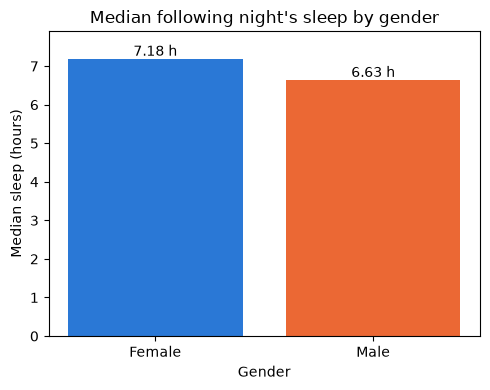

In [13]:
# Gender and A/B person (morning or evening type) come from the participant overview.
participants = pd.read_excel(DATA_DIR / "participant-overview.xlsx", header=1)
participants = participants.rename(columns={"Participant ID": "participant_id", "Gender": "gender", "A or B person": "ab_type"})
participants["gender"] = participants["gender"].str.strip().str.capitalize()
participants["ab_type"] = participants["ab_type"].str.strip()
nights = nights.drop(columns=["gender", "ab_type"], errors="ignore").merge(
    participants[["participant_id", "gender", "ab_type"]], on="participant_id", how="left"
)

median_sleep = nights.groupby("gender")["next_sleep_minutes"].median() / 60

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(median_sleep.index, median_sleep, color=["#2a78d6", "#eb6834"])
ax.bar_label(bars, fmt="%.2f h")
ax.set_ylim(0, median_sleep.max() * 1.1)
ax.set(title="Median following night's sleep by gender", xlabel="Gender", ylabel="Median sleep (hours)")
plt.tight_layout()
plt.show()

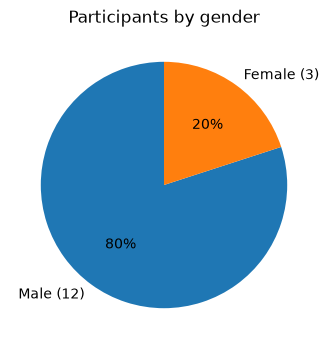

In [14]:
gender_counts = nights.drop_duplicates("participant_id")["gender"].value_counts()
fig, ax = plt.subplots(figsize=(4, 4))
ax.pie(gender_counts, labels=[f"{g} ({n})" for g, n in gender_counts.items()], autopct="%1.0f%%", startangle=90)
ax.set_title("Participants by gender")
plt.show()

We have more males hense more data, the model might become more favourable of the male during training, females sleep duration seems more than male, which is to be expected.

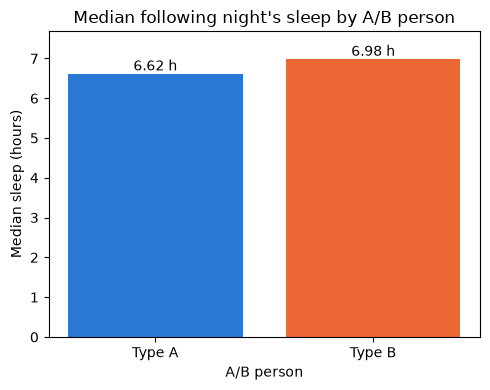

In [15]:
median_sleep_ab = nights.groupby("ab_type")["next_sleep_minutes"].median() / 60

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar([f"Type {t}" for t in median_sleep_ab.index], median_sleep_ab, color=["#2a78d6", "#eb6834"])
ax.bar_label(bars, fmt="%.2f h")
ax.set_ylim(0, median_sleep_ab.max() * 1.1)
ax.set(title="Median following night's sleep by A/B person", xlabel="A/B person", ylabel="Median sleep (hours)")
plt.tight_layout()
plt.show()

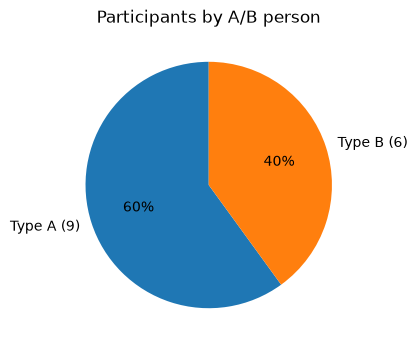

In [16]:
ab_counts = nights.drop_duplicates("participant_id")["ab_type"].value_counts()
fig, ax = plt.subplots(figsize=(4, 4))
ax.pie(ab_counts, labels=[f"Type {t} ({n})" for t, n in ab_counts.items()], autopct="%1.0f%%", startangle=90)
ax.set_title("Participants by A/B person")
plt.show()

Type A people stand for "A-menneske", which translated means morning person, while type B people stand for "B-menneske". evening people. The split is more even than the gender one, but it's also interesting that evening people on average sleep more than morning people.

In [17]:
training_load = pd.read_csv(participant_folders[0] / "pmsys/srpe.csv")
training_load.head()

,end_date_time,activity_names,perceived_exertion,duration_min
0,2019-11-05T22:51:54.710Z,"['individual', 'running']",7,30
1,2019-11-11T21:15:15.092Z,"['individual', 'running']",6,30
2,2019-11-14T21:00:53.000Z,"['team', 'soccer']",7,60
3,2019-11-18T21:34:44.995Z,"['individual', 'endurance']",6,50
4,2019-11-21T21:06:25.146Z,"['team', 'soccer']",6,70


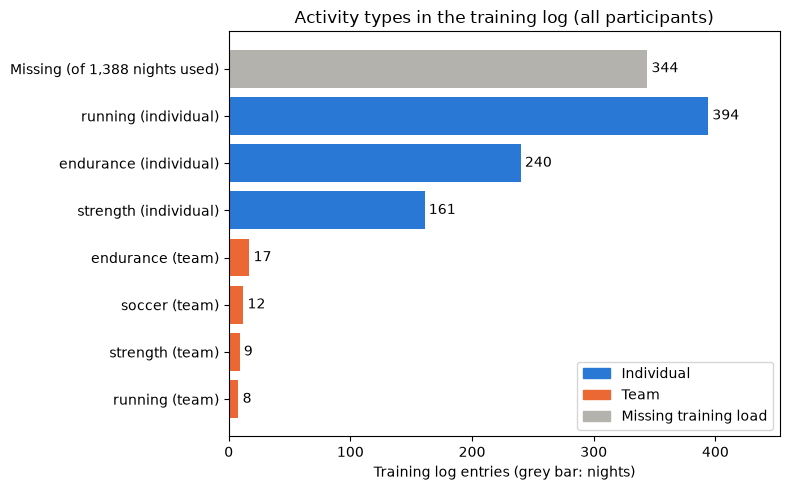

In [18]:
import ast

srpe_tables = []
for folder in participant_folders:
    records = pd.read_csv(folder / "pmsys/srpe.csv")
    records["participant_id"] = folder.name
    srpe_tables.append(records)
all_training = pd.concat(srpe_tables, ignore_index=True)

# activity_names holds a list such as ['individual', 'running']; empty entries have no list.
names = all_training["activity_names"].apply(lambda value: ast.literal_eval(value) if isinstance(value, str) and value.startswith("[") else [])

# Each entry is individual or team, followed by one or more activities.
entries = pd.DataFrame({
    "setting": names.apply(lambda items: next((item for item in items if item in ["individual", "team"]), None)),
    "activity": names.apply(lambda items: [item for item in items if item not in ["individual", "team"]]),
}).explode("activity").dropna(subset=["activity"])
activity_counts = entries.value_counts(["activity", "setting"]).sort_values()

# Nights we use that have no training load at all.
missing_nights = nights["training_load"].isna().sum()

bar_labels = [f"{activity} ({setting})" for activity, setting in activity_counts.index] + [f"Missing (of {len(nights):,} nights used)"]
bar_values = list(activity_counts) + [missing_nights]
bar_colors = ["#eb6834" if setting == "team" else "#2a78d6" for _, setting in activity_counts.index] + ["#b4b2ac"]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(bar_labels, bar_values, color=bar_colors)
ax.bar_label(bars, padding=3)
ax.set(title="Activity types in the training log (all participants)",
       xlabel="Training log entries (grey bar: nights)", ylabel="")
ax.set_xlim(0, max(bar_values) * 1.15)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=color) for color in ["#2a78d6", "#eb6834", "#b4b2ac"]],
          labels=["Individual", "Team", "Missing training load"], loc="lower right")
plt.tight_layout()
plt.show()

In [19]:
all_training.duplicated().sum()

np.int64(0)

## Step 2: Missing values

The wellness reports (1,147 nights) and the Google Docs reports (791 nights) cover far fewer nights than the Fitbit data (1,388). Since both reports will be used in iteration 2, I am planning to cut the table down to the nights that have both of them.

Before doing that, I want to check whether it would bias the data. If participants tend to skip their reports on unusual days, the nights without reports might sleep differently from the rest, and dropping them would change what the model learns. So I compare the following night's sleep on nights with and without both reports, per participant.

,size,mean,median,std
Has both reports,791.0,6.73,6.70,1.40
Missing a report,597.0,6.88,6.87,1.25
All explored nights,1388.0,6.79,6.75,1.34


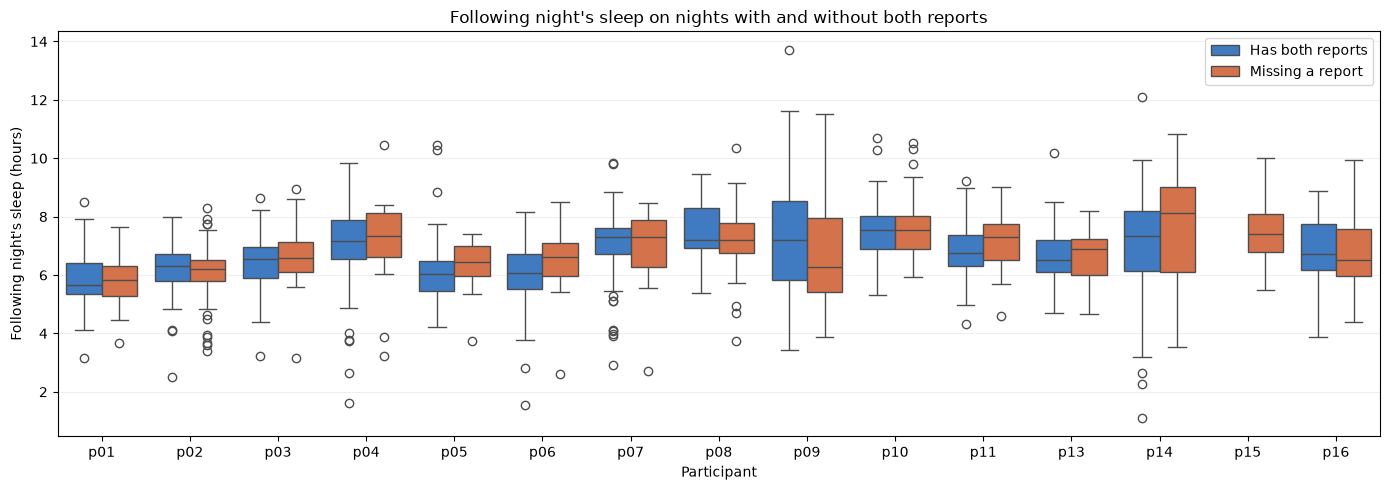

In [20]:
has_reports = nights["stress"].notna() & nights["meal_count"].notna()
report_groups = has_reports.map({True: "Has both reports", False: "Missing a report"})
nights["next_sleep_hours"] = nights["next_sleep_minutes"] / 60

sleep_summary = nights.groupby(report_groups)["next_sleep_hours"].agg(["size", "mean", "median", "std"])
sleep_summary.loc["All explored nights"] = nights["next_sleep_hours"].agg(["size", "mean", "median", "std"])
display(sleep_summary.round(2))

fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(
    data=nights, x="participant_id", y="next_sleep_hours", hue=report_groups,
    hue_order=["Has both reports", "Missing a report"], palette=["#2a78d6", "#eb6834"], ax=ax,
)
ax.set(title="Following night's sleep on nights with and without both reports",
       xlabel="Participant", ylabel="Following night's sleep (hours)")
ax.grid(axis="y", alpha=0.2)
ax.legend(title="")
plt.tight_layout()
plt.show()

To go deeper, I look at every column on its own. First, which columns have missing values, and how much is missing in each?

In [21]:
missing = nights.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({
    "Missing nights": missing,
    "Missing (%)": (missing / len(nights) * 100).round(1),
})

,Missing nights,Missing (%)
drank_alcohol,603,43.4
meal_count,597,43.0
had_breakfast,597,43.0
had_evening_meal,597,43.0
glasses_of_fluid,597,43.0
training_load,344,24.8
readiness,241,17.4
reported_sleep_hours,241,17.4
fatigue,241,17.4
stress,241,17.4


Then, for each of those columns, I compare the following night's sleep on nights where the value is missing with nights where it is present. If the two are clearly different for a column, its missing values are related to sleep, and dropping those nights would bias the data.

,Present nights,Missing nights,Median when present (h),Median when missing (h),Missing minus present (min)
Column,,,,,
drank_alcohol,785,603,6.70,6.87,10.0
meal_count,791,597,6.70,6.87,10.0
had_breakfast,791,597,6.70,6.87,10.0
had_evening_meal,791,597,6.70,6.87,10.0
glasses_of_fluid,791,597,6.70,6.87,10.0
training_load,1044,344,6.87,6.48,-23.0
readiness,1147,241,6.75,6.75,0.0
reported_sleep_hours,1147,241,6.75,6.75,0.0
fatigue,1147,241,6.75,6.75,0.0


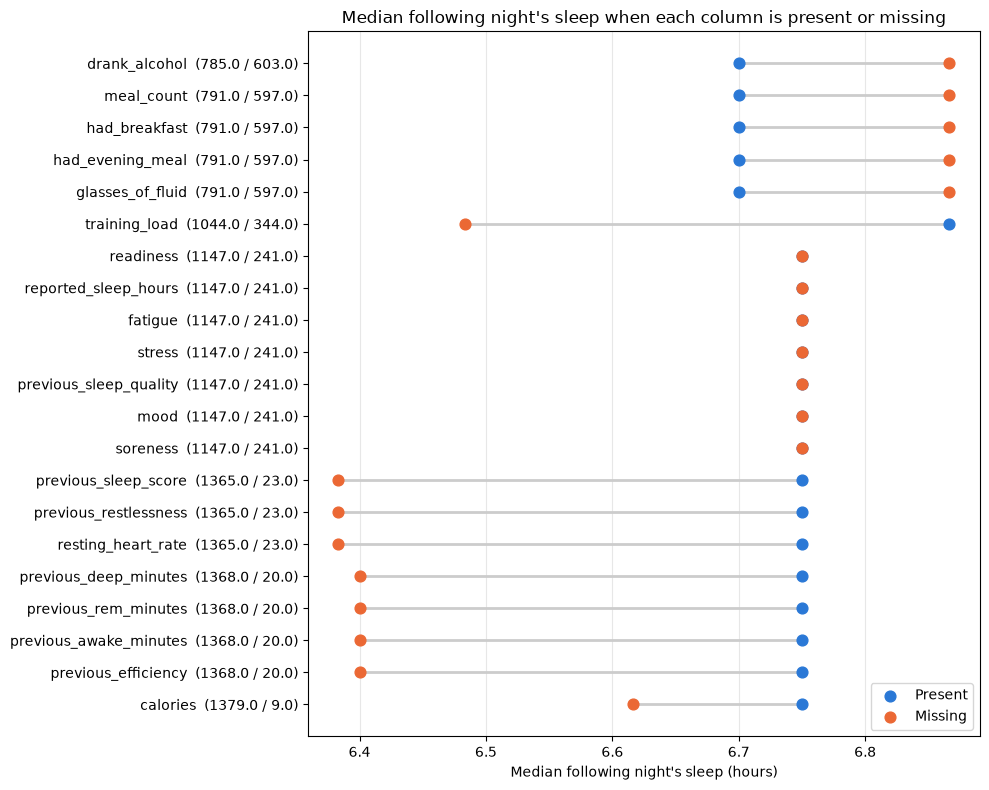

In [22]:
missing_vs_present = pd.DataFrame([
    {
        "Column": column,
        "Present nights": nights[column].notna().sum(),
        "Missing nights": nights[column].isna().sum(),
        "Median when present (h)": nights.loc[nights[column].notna(), "next_sleep_hours"].median(),
        "Median when missing (h)": nights.loc[nights[column].isna(), "next_sleep_hours"].median(),
    }
    for column in missing.index
]).set_index("Column")
missing_vs_present["Missing minus present (min)"] = (
    (missing_vs_present["Median when missing (h)"] - missing_vs_present["Median when present (h)"]) * 60
).round(0)
display(missing_vs_present.round(2))

positions = np.arange(len(missing_vs_present))[::-1]
fig, ax = plt.subplots(figsize=(10, 8))
ax.hlines(positions, missing_vs_present["Median when present (h)"], missing_vs_present["Median when missing (h)"],
          color="#cccccc", linewidth=2)
ax.scatter(missing_vs_present["Median when present (h)"], positions, color="#2a78d6", s=60, zorder=3, label="Present")
ax.scatter(missing_vs_present["Median when missing (h)"], positions, color="#eb6834", s=60, zorder=3, label="Missing")
ax.set_yticks(positions, [
    f"{column}  ({row['Present nights']} / {row['Missing nights']})" for column, row in missing_vs_present.iterrows()
])
ax.set(title="Median following night's sleep when each column is present or missing",
       xlabel="Median following night's sleep (hours)")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

The effect does not go the same way for every column. For the Google Docs columns (alcohol, meal count, breakfast, evening meal and fluid), the following night's sleep is about **10 minutes longer when the value is missing** (6.87 h against 6.70 h). For training load and the Fitbit sleep details it is the other way around: sleep is about **21–23 minutes shorter when they are missing**, although the sleep details are only missing on 20–23 nights. The wellness scores make no difference (6.75 h both ways).

The five Google Docs columns are missing on the same 597 nights (603 for alcohol), so they go missing together, whenever the whole daily report is missing. The 10 minutes therefore belong to the missing report, and can't directly be atributed to a specific feature, whether alcohol or meals change sleep is checked later, when each feature is compared with the target.

Since the nights without a daily report sleep longer, they are the ones to look into more closely before deciding to cut them.

Next I want to see whether the nights without a daily report are different days in other ways, which might explain the longer sleep. I compare the columns that are recorded on every night (the Fitbit sleep and activity, and the weekday) on nights with and without a daily report.

,With daily report,Without daily report
previous_sleep_minutes,401.41,411.28
previous_bedtime_hour,0.22,0.68
wake_up_hour,8.03,8.53
steps,10786.69,10340.19
session_count,1.07,1.12
very_active_minutes,27.42,37.59
weekend_night,0.29,0.27


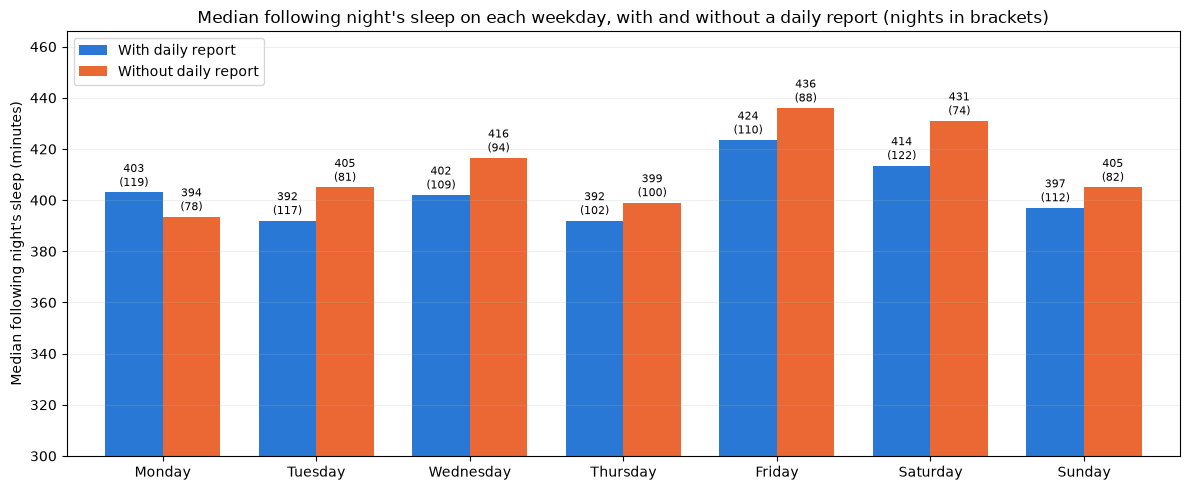

In [23]:
has_daily_report = nights["meal_count"].notna()
report_label = has_daily_report.map({True: "With daily report", False: "Without daily report"})

complete_columns = [
    "previous_sleep_minutes", "previous_bedtime_hour", "wake_up_hour",
    "steps", "session_count", "very_active_minutes", "weekend_night",
]
other_days = nights.groupby(report_label)[complete_columns].mean().T
other_days.columns.name = None
display(other_days.round(2))

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_sleep = nights.groupby(["weekday", report_label])["next_sleep_minutes"].median().unstack().reindex(weekday_order)
weekday_nights = nights.groupby(["weekday", report_label]).size().unstack().reindex(weekday_order)

fig, ax = plt.subplots(figsize=(12, 5))
bars = weekday_sleep[["With daily report", "Without daily report"]].plot.bar(
    color=["#2a78d6", "#eb6834"], width=0.75, ax=ax,
)
for container, group in zip(ax.containers, ["With daily report", "Without daily report"]):
    labels = [f"{minutes:.0f}\n({count})" for minutes, count in zip(weekday_sleep[group], weekday_nights[group])]
    ax.bar_label(container, labels=labels, fontsize=8, padding=2)
# The axis starts at 300 minutes, so the differences between the bars are visible.
ax.set_ylim(300, weekday_sleep.max().max() + 30)
ax.set(title="Median following night's sleep on each weekday, with and without a daily report (nights in brackets)",
       xlabel="", ylabel="Median following night's sleep (minutes)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(title="", loc="upper left")
plt.tight_layout()
plt.show()

On days without a daily report, participants went to bed later the night before (around 00:41 against 00:13), woke up later (around 08:32 against 08:02) and had more very active minutes (38 against 27). Steps, exercise sessions and the previous night's sleep are close in both groups. These differences could explain part of the longer sleep, but the table does not show that very active minutes or bedtime themselves change sleep; that is checked when each feature is compared with the target.

Friday and Saturday nights are the longest in both groups. The nights without a report are not more often weekends, though: 27% of them are weekend nights against 29% of the nights with a report, and the number of nights without a report on Friday (88) and Saturday (74) is similar to the other days. On six of the seven days, nights without a report are longer than nights with one (Monday is the exception), so the weekend does not explain the longer sleep on nights without a report.

To go one step deeper, I want to see the same comparison per participant: for each person, the median of the key metrics on days with and without a daily report. This shows whether the differences hold for everyone or come from a few people.

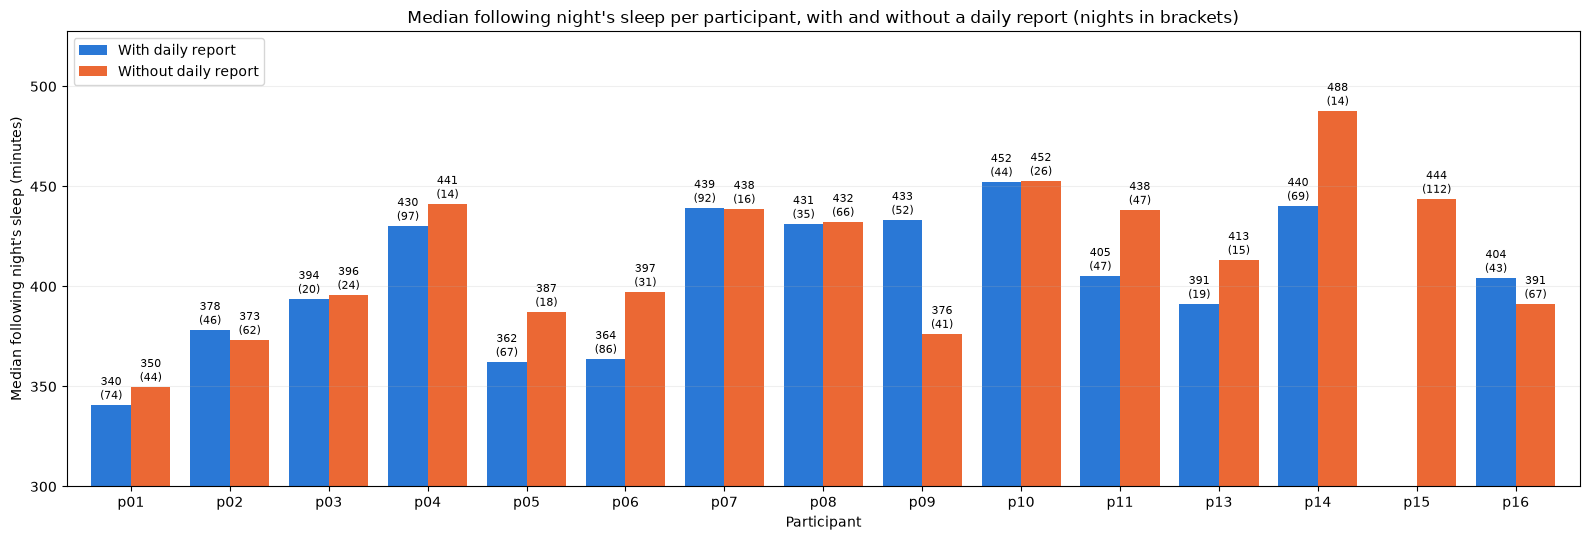

In [24]:
participants = sorted(nights["participant_id"].unique())
person_sleep = nights.groupby(["participant_id", report_label])["next_sleep_minutes"].median().unstack().reindex(participants)
person_nights = nights.groupby(["participant_id", report_label]).size().unstack().reindex(participants).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(16, 5.5))
person_sleep[["With daily report", "Without daily report"]].plot.bar(color=["#2a78d6", "#eb6834"], width=0.8, ax=ax)
for container, group in zip(ax.containers, ["With daily report", "Without daily report"]):
    labels = [
        "" if pd.isna(minutes) else f"{minutes:.0f}\n({count})"
        for minutes, count in zip(person_sleep[group], person_nights[group])
    ]
    ax.bar_label(container, labels=labels, fontsize=8, padding=2)
# The axis starts at 300 minutes, so the differences between the bars are visible.
ax.set_ylim(300, person_sleep.max().max() + 40)
ax.set(title="Median following night's sleep per participant, with and without a daily report (nights in brackets)",
       xlabel="Participant", ylabel="Median following night's sleep (minutes)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(title="", loc="upper left")
plt.tight_layout()
plt.show()

Some people have a big difference in their sleep between nights with and without a report, and some don't. p02, p03, p07, p08 and p10 are rather consistent: their sleep is about the same on both kinds of nights, sometimes slightly more with a report and sometimes slightly more without. The rest show a bigger difference, so they are worth exploring to find out why.

To look for a pattern, I will split the participants into two groups: the **consistent** ones above, and the **inconsistent** ones (everyone else, except p15, who has no nights with a report to compare).

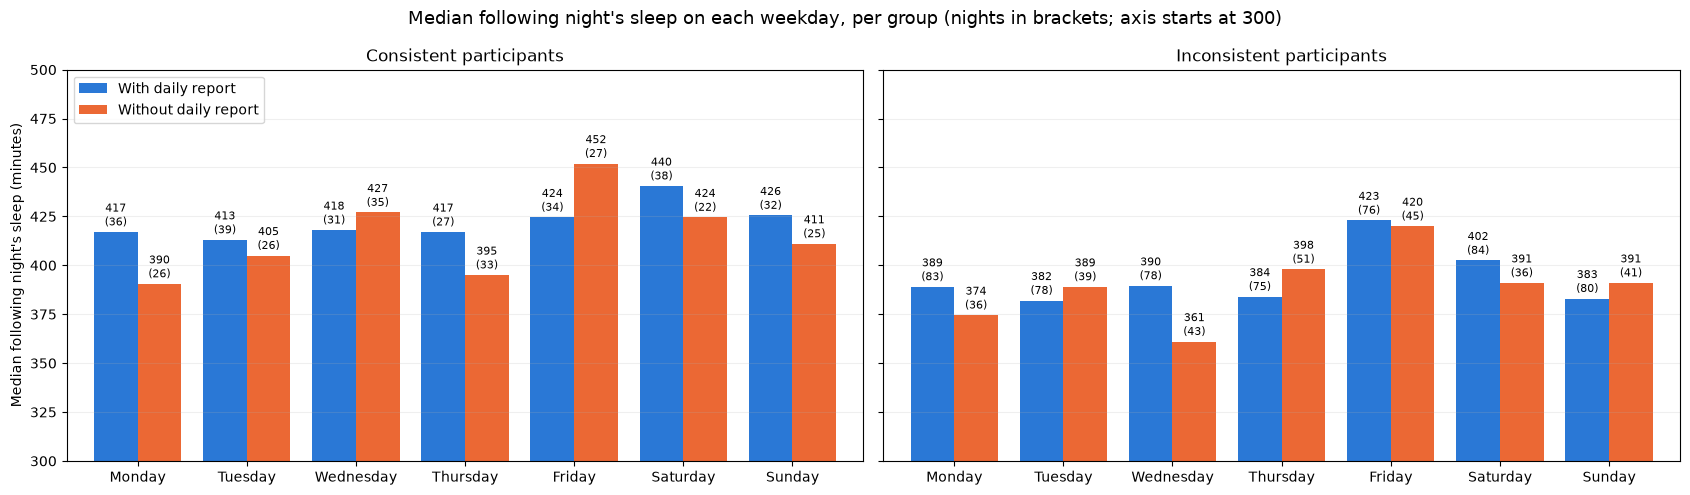

In [25]:
consistent_people = ["p02", "p03", "p07", "p08", "p10"]
inconsistent_people = ["p01", "p04", "p05", "p06", "p09", "p11", "p13", "p14", "p16"]

sleeper_group = nights["participant_id"].map(
    {person: "Consistent" for person in consistent_people}
    | {person: "Inconsistent" for person in inconsistent_people}
)
compared = nights.loc[sleeper_group.notna()]

fig, axes = plt.subplots(1, 2, figsize=(17, 5), sharey=True)
for ax, group in zip(axes, ["Consistent", "Inconsistent"]):
    in_group = compared.loc[sleeper_group == group]
    group_report = report_label.loc[in_group.index]
    sleep = in_group.groupby(["weekday", group_report])["next_sleep_minutes"].median().unstack().reindex(weekday_order)
    count = in_group.groupby(["weekday", group_report]).size().unstack().reindex(weekday_order)
    sleep[["With daily report", "Without daily report"]].plot.bar(color=["#2a78d6", "#eb6834"], width=0.8, ax=ax, legend=False)
    for container, column in zip(ax.containers, ["With daily report", "Without daily report"]):
        ax.bar_label(container, labels=[f"{m:.0f}\n({n})" for m, n in zip(sleep[column], count[column])], fontsize=8, padding=2)
    ax.set_ylim(300, 500)
    ax.set(title=f"{group} participants", xlabel="", ylabel="Median following night's sleep (minutes)")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.2)
axes[0].legend(["With daily report", "Without daily report"], loc="upper left")
fig.suptitle("Median following night's sleep on each weekday, per group (nights in brackets; axis starts at 300)", fontsize=13)
plt.tight_layout()
plt.show()

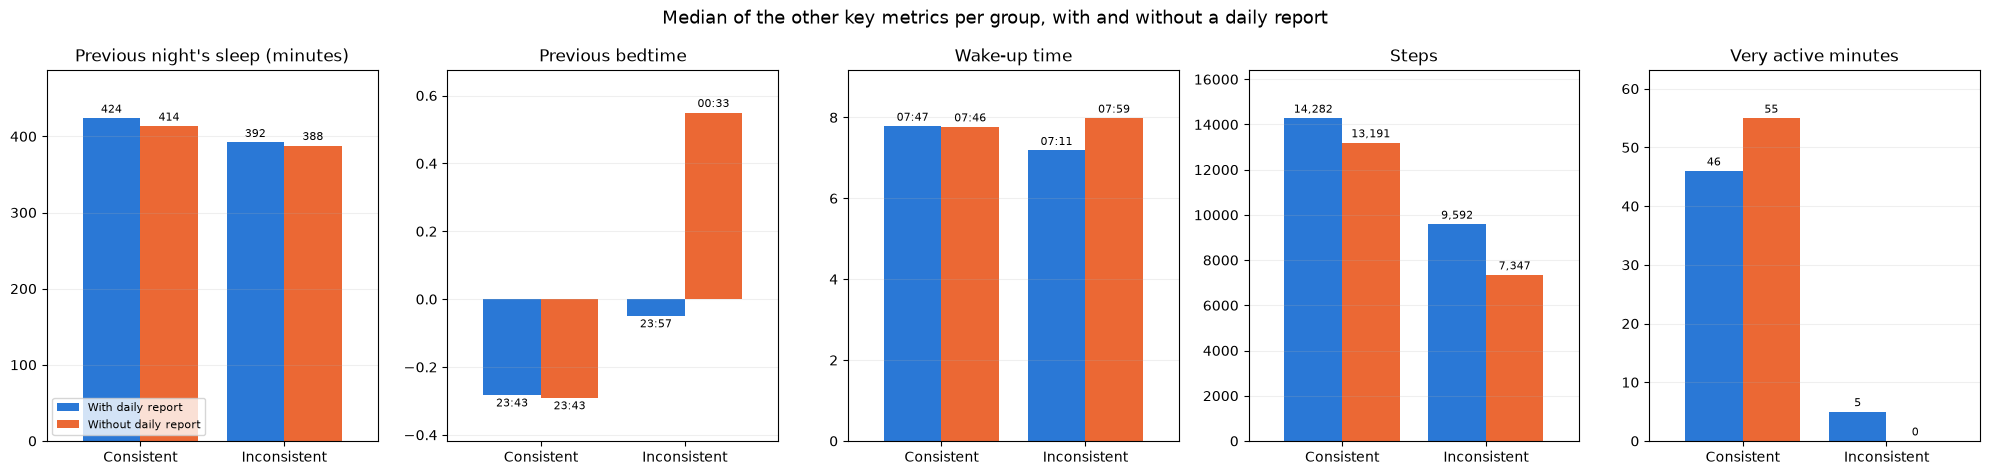

,With daily report,Without daily report
Group,,
Consistent,237,194
Inconsistent,554,291


In [26]:
group_metrics = {
    "previous_sleep_minutes": ("Previous night's sleep (minutes)", lambda v: f"{v:.0f}"),
    "previous_bedtime_hour": ("Previous bedtime", lambda v: f"{int((v % 24) // 1):02d}:{int(round((v % 1) * 60)) % 60:02d}"),
    "wake_up_hour": ("Wake-up time", lambda v: f"{int(v // 1):02d}:{int(round((v % 1) * 60)) % 60:02d}"),
    "steps": ("Steps", lambda v: f"{v:,.0f}"),
    "very_active_minutes": ("Very active minutes", lambda v: f"{v:.0f}"),
}
group_nights = compared.groupby([sleeper_group, report_label]).size().unstack()

fig, axes = plt.subplots(1, 5, figsize=(20, 4.8))
for ax, (column, (title, as_text)) in zip(axes, group_metrics.items()):
    medians = compared.groupby([sleeper_group, report_label.loc[compared.index]])[column].median().unstack()
    medians = medians.reindex(columns=["With daily report", "Without daily report"])
    medians.plot.bar(color=["#2a78d6", "#eb6834"], width=0.8, ax=ax, legend=False)
    for container, report in zip(ax.containers, medians.columns):
        ax.bar_label(container, labels=[as_text(v) for v in medians[report]], fontsize=8, padding=2)
    ax.set(title=title, xlabel="")
    ax.tick_params(axis="x", rotation=0)
    ax.margins(y=0.15)
    ax.grid(axis="y", alpha=0.2)
axes[0].legend(["With daily report", "Without daily report"], loc="lower left", fontsize=8)
fig.suptitle("Median of the other key metrics per group, with and without a daily report", fontsize=13)
plt.tight_layout()
plt.show()

group_nights.rename_axis(index="Group", columns=None)

The consistent participants keep a steady routine: they go to bed before 00:00 and wake up at before 08:00 on both kinds of nights. The inconsistent participants shift on days without a report: they went to bed later (00:33 against 23:57) and woke up later (07:59 against 07:11), which could be part of why their sleep differs. The consistent participants are also more active, with around 13,000–14,000 steps against 7,000–9,500, and 46–55 very active minutes against 0–5.

The inconsistent group does not have more records per person (about 94 nights against 86 for the consistent group); it is bigger because it has more people. But several inconsistent participants have very few nights without a report (p04 and p14 have 14, p13 has 15, p05 has 18). A median of so few nights can land far from the usual value by chance, so part of their big difference may be noise rather than a real change in sleep.

Maybe the inconsistent participants are simply irregular sleepers in general, whether they report or not. If so, their big difference between nights with and without a report would just be their normal irregularity. To check this, I look at how much each participant's sleep duration and bedtime vary across all their nights.

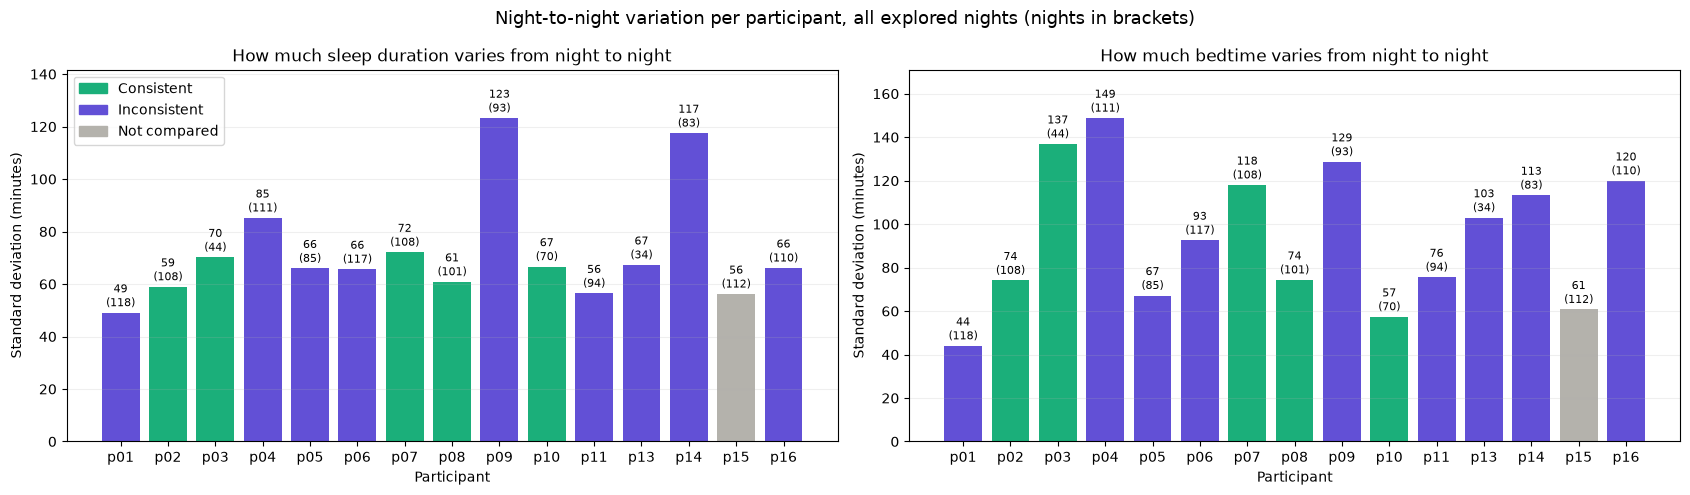

In [27]:
participants = sorted(nights["participant_id"].unique())
regularity = pd.DataFrame({
    "Sleep duration": nights.groupby("participant_id")["next_sleep_minutes"].std(),
    "Bedtime": nights.groupby("participant_id")["previous_bedtime_hour"].std() * 60,
}).reindex(participants)
person_group = pd.Series(
    {person: "Consistent" for person in consistent_people}
    | {person: "Inconsistent" for person in inconsistent_people}
).reindex(participants).fillna("Not compared")
group_colors = {"Consistent": "#1baf7a", "Inconsistent": "#6250d6", "Not compared": "#b4b2ac"}
person_count = nights.groupby("participant_id").size().reindex(participants)

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, column in zip(axes, regularity.columns):
    bars = ax.bar(participants, regularity[column], color=person_group.map(group_colors))
    ax.bar_label(bars, labels=[f"{value:.0f}\n({count})" for value, count in zip(regularity[column], person_count)],
                 fontsize=8, padding=2)
    ax.set(title=f"How much {column.lower()} varies from night to night",
           ylabel="Standard deviation (minutes)", xlabel="Participant")
    ax.margins(y=0.15)
    ax.grid(axis="y", alpha=0.2)
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=color) for color in group_colors.values()],
               labels=list(group_colors), loc="upper left")
fig.suptitle("Night-to-night variation per participant, all explored nights (nights in brackets)", fontsize=13)
plt.tight_layout()
plt.show()

The theory of consistent and inconsistent sleepers does not really hold up. The consistent participants' sleep duration varies by 59–72 minutes from night to night, and most inconsistent participants fall in the same range (49–67 minutes), so being an irregular sleeper in general does not explain the split. p01 is even the most regular of everyone (49 minutes for sleep, 44 for bedtime). Only p09 (123 minutes) and p14 (117 minutes) are clearly irregular sleepers, and p04 has the most irregular bedtime (149 minutes).

For several inconsistent participants, the big difference more likely comes from having few nights without a report: p04 and p14 have only 14, p13 has 15 and p05 has 18, and with so few nights a big gap can appear by chance.

I want to see whether nights without a training load sleep differently from nights with one, first per participant and then per weekday, the same way as for the reports.

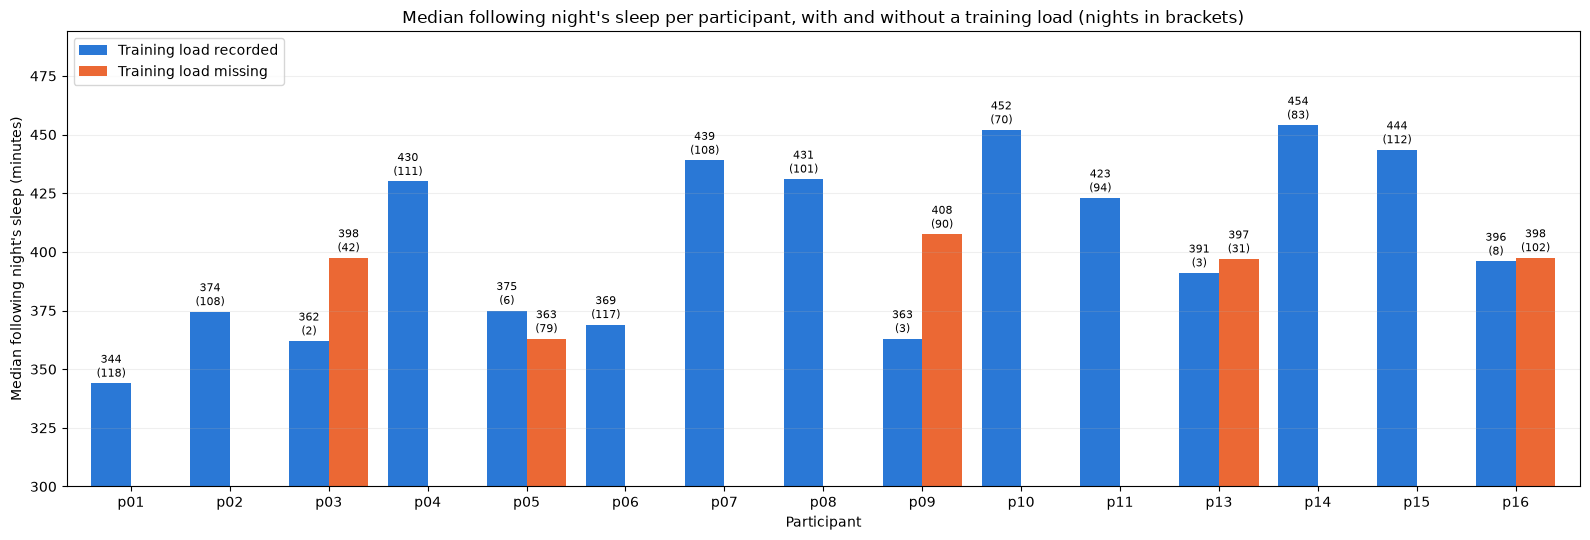

In [28]:
training_label = nights["training_load"].isna().map({False: "Training load recorded", True: "Training load missing"})
groups = ["Training load recorded", "Training load missing"]
participants = sorted(nights["participant_id"].unique())

person_sleep = nights.groupby(["participant_id", training_label])["next_sleep_minutes"].median().unstack().reindex(index=participants, columns=groups)
person_nights = nights.groupby(["participant_id", training_label]).size().unstack().reindex(index=participants, columns=groups).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(16, 5.5))
person_sleep.plot.bar(color=["#2a78d6", "#eb6834"], width=0.8, ax=ax)
for container, group in zip(ax.containers, groups):
    labels = ["" if pd.isna(minutes) else f"{minutes:.0f}\n({count})" for minutes, count in zip(person_sleep[group], person_nights[group])]
    ax.bar_label(container, labels=labels, fontsize=8, padding=2)
# The axis starts at 300 minutes, so the differences between the bars are visible.
ax.set_ylim(300, person_sleep.max().max() + 40)
ax.set(title="Median following night's sleep per participant, with and without a training load (nights in brackets)",
       xlabel="Participant", ylabel="Median following night's sleep (minutes)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(title="", loc="upper left")
plt.tight_layout()
plt.show()

the missing training nights come from a few people only

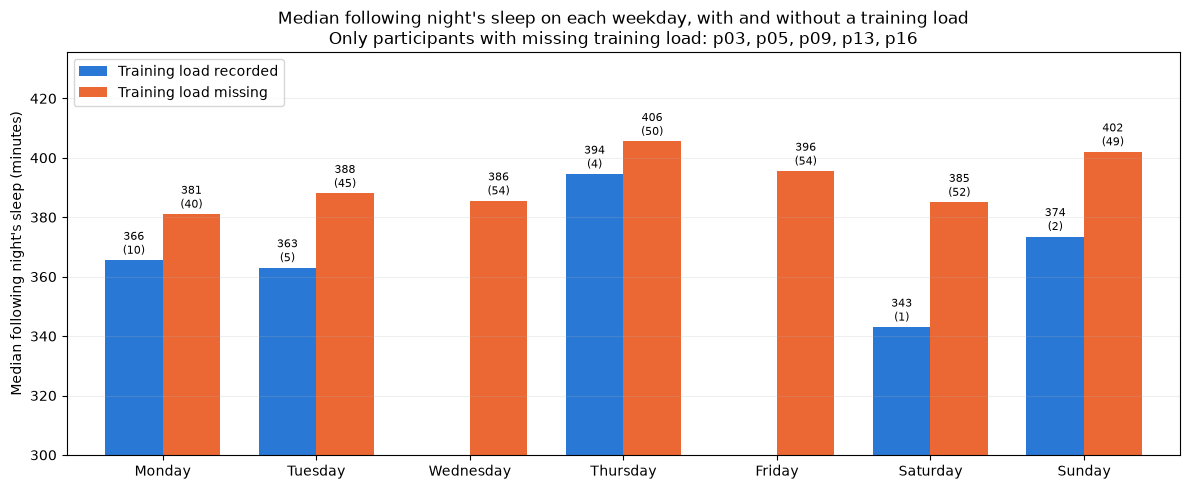

In [29]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
# Only the participants who have nights without a training load.
people_with_missing = sorted(nights.loc[nights["training_load"].isna(), "participant_id"].unique())
with_missing = nights.loc[nights["participant_id"].isin(people_with_missing)]
with_missing_label = training_label.loc[with_missing.index]

weekday_sleep = with_missing.groupby(["weekday", with_missing_label])["next_sleep_minutes"].median().unstack().reindex(index=weekday_order, columns=groups)
weekday_nights = with_missing.groupby(["weekday", with_missing_label]).size().unstack().reindex(index=weekday_order, columns=groups).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(12, 5))
weekday_sleep.plot.bar(color=["#2a78d6", "#eb6834"], width=0.75, ax=ax)
for container, group in zip(ax.containers, groups):
    labels = ["" if pd.isna(minutes) else f"{minutes:.0f}\n({count})" for minutes, count in zip(weekday_sleep[group], weekday_nights[group])]
    ax.bar_label(container, labels=labels, fontsize=8, padding=2)
ax.set_ylim(300, weekday_sleep.max().max() + 30)
ax.set(title="Median following night's sleep on each weekday, with and without a training load\n"
             f"Only participants with missing training load: {', '.join(people_with_missing)}",
       xlabel="", ylabel="Median following night's sleep (minutes)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(title="", loc="upper left")
plt.tight_layout()
plt.show()

p03, p05, p09, p13 and p16 barely record their training compared to the other participants, only 2 to 8 recorded nights each, so for them a missing training load mostly means they did not use the log, not that they did not train, maybe the values would be found in the fitbit files.

A "None" in `last_activity` means that the Fitbit recorded no exercise session that day. It looks like a real value, but some of these days might have had training that the watch missed. First, I want to see where these "None" days are.

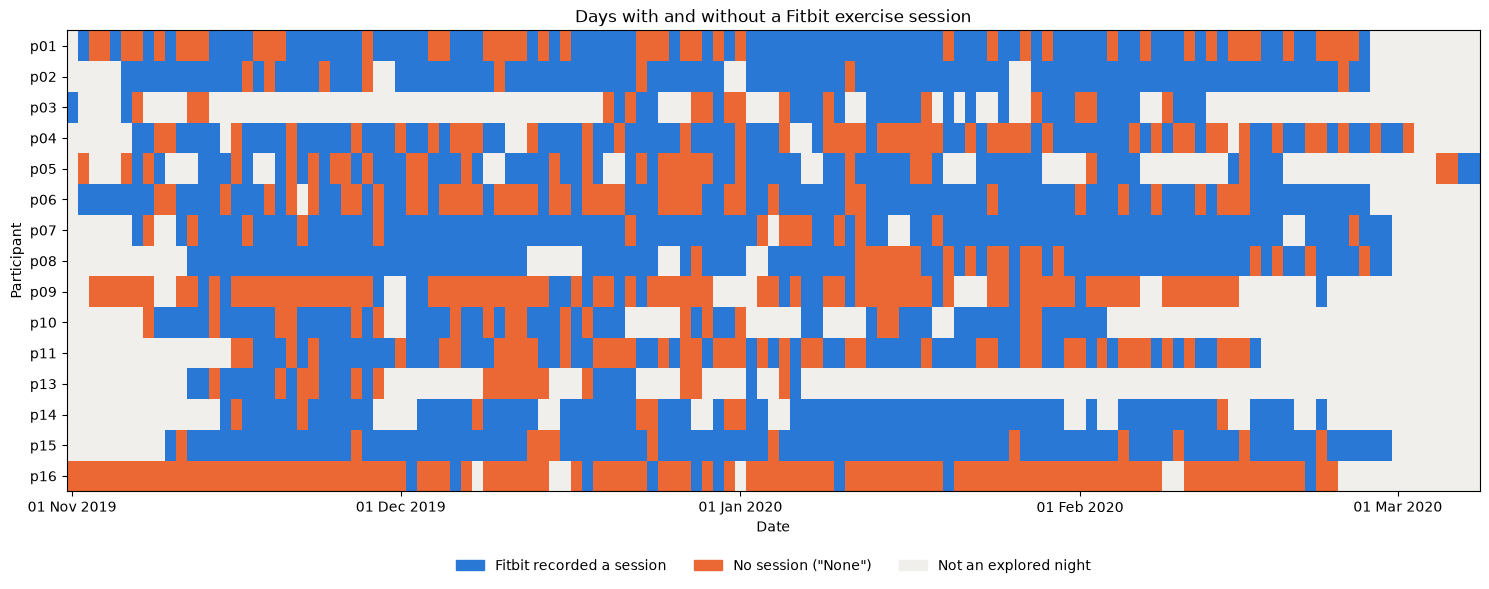

"None" days: 489 of 1,388 explored nights


In [30]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

participants = sorted(nights["participant_id"].unique())
calendar_dates = pd.date_range(nights["date"].min(), nights["date"].max())
# 1 = Fitbit recorded a session, 2 = "None"; days that are not explored stay 0.
day_status = nights.assign(status=np.where(nights["last_activity"].eq("None"), 2, 1))
calendar = day_status.pivot(index="participant_id", columns="date", values="status").reindex(
    index=participants, columns=calendar_dates
).fillna(0)

month_starts = [i for i, day in enumerate(calendar_dates) if day.day == 1]
fig, ax = plt.subplots(figsize=(15, 6))
ax.imshow(calendar, aspect="auto", interpolation="nearest", cmap=ListedColormap(["#f0efec", "#2a78d6", "#eb6834"]), vmin=-0.5, vmax=2.5)
ax.set_yticks(range(len(participants)), participants)
ax.set_xticks(month_starts, [calendar_dates[i].strftime("%d %b %Y") for i in month_starts])
ax.set(title="Days with and without a Fitbit exercise session", xlabel="Date", ylabel="Participant")
ax.legend(handles=[Patch(color="#2a78d6", label="Fitbit recorded a session"),
                   Patch(color="#eb6834", label='No session ("None")'),
                   Patch(color="#f0efec", label="Not an explored night")],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

print(f'"None" days: {nights["last_activity"].eq("None").sum():,} of {len(nights):,} explored nights')

Next, I want to see whether the training log and the Fitbit overlap at all: on each day, did the Fitbit record a session, did the training log have one, both, or neither? The days where only the training log has a session are the ones that could fill in a "None".

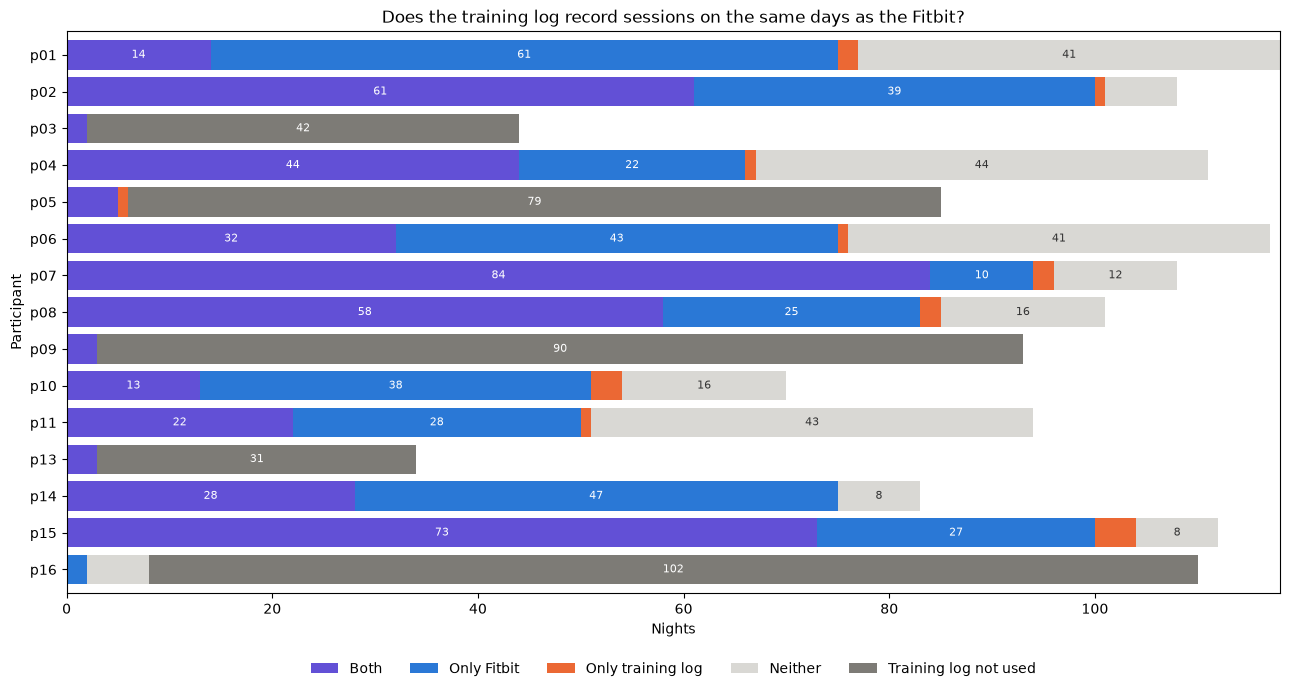

,Both,Only Fitbit,Only training log,Neither,Training log not used
Nights,442,342,18,242,344


In [31]:
fitbit_session = nights["last_activity"].ne("None")
log_session = nights["training_load"].gt(0)
match = np.select(
    [nights["training_load"].isna(), fitbit_session & log_session, fitbit_session, log_session],
    ["Training log not used", "Both", "Only Fitbit", "Only training log"],
    default="Neither",
)
match_order = ["Both", "Only Fitbit", "Only training log", "Neither", "Training log not used"]
match_colors = ["#6250d6", "#2a78d6", "#eb6834", "#d9d8d4", "#7d7b76"]
match_counts = pd.crosstab(nights["participant_id"], match).reindex(index=participants, columns=match_order, fill_value=0)

fig, ax = plt.subplots(figsize=(13, 7))
match_counts.iloc[::-1].plot.barh(stacked=True, color=match_colors, width=0.8, ax=ax)
for container, group in zip(ax.containers, match_order):
    ax.bar_label(container, labels=[str(int(v)) if v >= 8 else "" for v in container.datavalues],
                 label_type="center", fontsize=8, color="#333333" if group == "Neither" else "white")
ax.set(title="Does the training log record sessions on the same days as the Fitbit?",
       xlabel="Nights", ylabel="Participant")
ax.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=5, frameon=False)
plt.tight_layout()
plt.show()

match_counts.sum().rename_axis(None).to_frame("Nights").T

Fitbit entries seem to be more than the training log data, this could be due to fitbit counting walking as an activity, which traininglog doesn't. Just 18 days actually have data for workingout in the training log that isn't avaliable in the fitbit data. The 18 records might prove to be too little and have almost no impact.

To check whether the extra Fitbit days are walks, I look at which activity the Fitbit recorded as the last session on the days where only the Fitbit has a session.

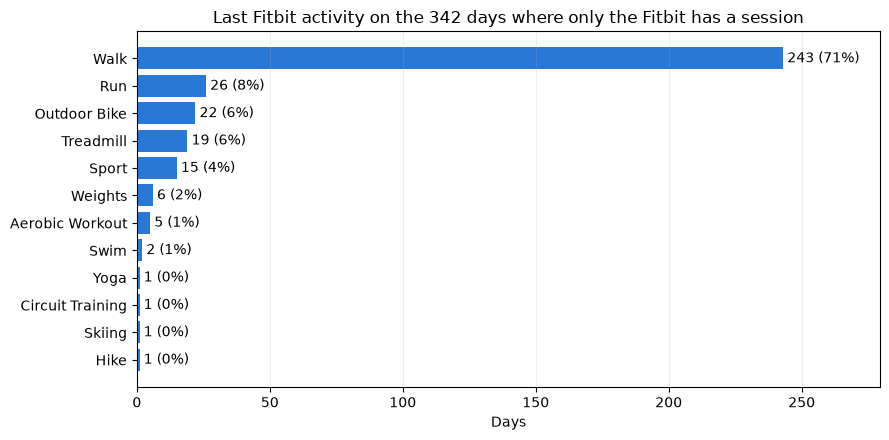

In [32]:
only_fitbit_activity = nights.loc[match == "Only Fitbit", "last_activity"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(only_fitbit_activity.index, only_fitbit_activity.values, color="#2a78d6")
ax.bar_label(bars, labels=[f"{n} ({n / only_fitbit_activity.sum():.0%})" for n in only_fitbit_activity.values], padding=3)
ax.set(title=f"Last Fitbit activity on the {only_fitbit_activity.sum()} days where only the Fitbit has a session",
       xlabel="Days", ylabel="")
ax.margins(x=0.15)
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

Just as I thought, most of the "workouts" are walking sessions, but what's interesting is that fitbit has quite a bit of running records too, these might be useful for filling data in missing training logs. However, the running sessions are only 26 days (8%), which is not much, and the training log is not something we are going to use for now. If feature selection shows that the activity type (`last_activity`) matters for sleep, this can be looked into again.

Finally, I want to compare the missing values with each other: are the same reports missing on the same days, or does each source go missing on different days?

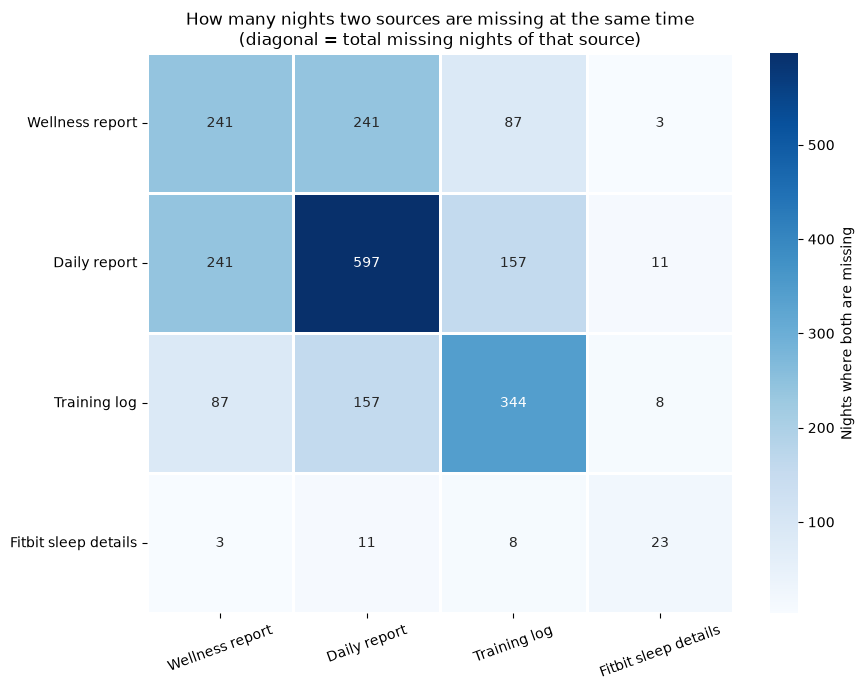

In [33]:
sources = {
    "Wellness report": "stress",
    "Daily report": "meal_count",
    "Training log": "training_load",
    "Fitbit sleep details": "previous_sleep_score",
}
missing_by_source = pd.DataFrame({name: nights[column].isna() for name, column in sources.items()}).astype(int)

# Nights where both the row source and the column source are missing; the diagonal is each source's total.
both_missing = missing_by_source.T @ missing_by_source

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(both_missing, annot=True, fmt="d", cmap="Blues", linewidths=1, linecolor="white",
            cbar_kws={"label": "Nights where both are missing"}, ax=ax)
ax.set(title="How many nights two sources are missing at the same time\n(diagonal = total missing nights of that source)",
       xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=20)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

The daily report is missing most often (597 nights). All 241 nights without a wellness report are also missing the daily report, so the wellness gaps sit completely inside the daily-report gaps. The training log overlaps partly: about half of its 344 missing nights (157) also miss the daily report.

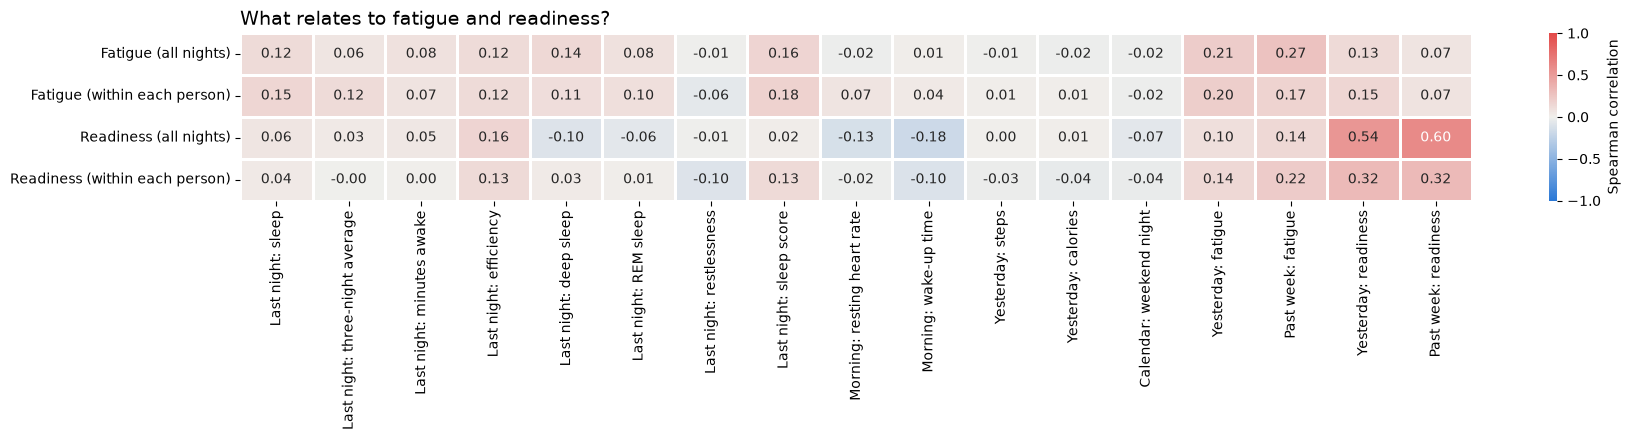

In [34]:
from matplotlib.colors import LinearSegmentedColormap

by_date = nights.sort_values(["participant_id", "date"])
previous_row = by_date.groupby("participant_id").shift(1)
day_before = (by_date["date"] - previous_row["date"]).eq(pd.Timedelta(days=1))

available = pd.DataFrame({
    "Last night: sleep": by_date["previous_sleep_minutes"],
    "Last night: three-night average": by_date["avg_sleep_last_3_nights"],
    "Last night: minutes awake": by_date["previous_awake_minutes"],
    "Last night: efficiency": by_date["previous_efficiency"],
    "Last night: deep sleep": by_date["previous_deep_minutes"],
    "Last night: REM sleep": by_date["previous_rem_minutes"],
    "Last night: restlessness": by_date["previous_restlessness"],
    "Last night: sleep score": by_date["previous_sleep_score"],
    "Morning: resting heart rate": by_date["resting_heart_rate"],
    "Morning: wake-up time": by_date["wake_up_hour"],
    "Yesterday: steps": previous_row["steps"].where(day_before),
    "Yesterday: calories": previous_row["calories"].where(day_before),
    "Calendar: weekend night": by_date["weekend_night"],
})
for score in ["fatigue", "readiness"]:
    available[f"Yesterday: {score}"] = previous_row[score].where(day_before)
    available[f"Past week: {score}"] = (
        by_date.groupby("participant_id").rolling("7D", on="date", closed="left")[score].mean().to_numpy()
    )

rows = {}
for score in ["fatigue", "readiness"]:
    table = available.assign(target=by_date[score])
    rows[f"{score.capitalize()} (all nights)"] = table.corr(method="spearman")["target"].drop("target")
    within = table.sub(table.groupby(by_date["participant_id"]).transform("mean"))
    rows[f"{score.capitalize()} (within each person)"] = within.corr(method="spearman")["target"].drop("target")
relations = pd.DataFrame(rows).T

fig, ax = plt.subplots(figsize=(18, 4.5))
sns.heatmap(relations, annot=True, fmt=".2f", cmap=LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"]),
            vmin=-1, vmax=1, center=0, linewidths=1, linecolor="white", cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("What relates to fatigue and readiness?", loc="left", fontsize=14)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

### What I decide about the missing values
- I keep the nights without reports instead of cutting them: they sleep about 10 minutes longer than the nights with a report, so cutting them would shift the data.
- p15 is dropped completely. They have no nights with a daily report, so there are no earlier values of their own to fill the gaps with.
- For everyone else, a missing report value will be handled later.
- The training log is not filled in. Five participants (p03, p05, p09, p13 and p16) barely used it, so for them a missing training load means the log was not used, not that they did not train. Whether training load is worth keeping is decided during feature selection.
- A "None" in `last_activity` is kept as "no exercise that day". The training log only has a session on 18 of those days, too few to be worth filling in, but perhaps i will end up doing that.
- On the days where only the Fitbit has a session, 71% of the sessions are walks, which the training log does not record. The 26 runs could fill training-log gaps, but this only matters if activity turns out to affect sleep.

In [35]:
candidates = candidates.loc[candidates["participant_id"] != "p15"].reset_index(drop=True)
nights = nights.loc[nights["participant_id"] != "p15"].reset_index(drop=True)
print(f"Explored nights without p15: {len(nights):,} from {nights['participant_id'].nunique()} participants")

Explored nights without p15: 1,276 from 14 participants


## Step 3: Numerical features

Not every column that holds numbers is a real measurement. Some are amounts that can take many values, like steps or minutes slept; others are categories written as numbers, like yes/no answers (0 or 1) or the 1–5 scores. A histogram only makes sense for the measurements, so first I sort the columns: for each one, how many different values it has and a few examples of them.

In [36]:
inputs_to_sort = nights.columns.drop(["participant_id", "date", "next_sleep_minutes", "next_sleep_hours"], errors="ignore")


def describe_values(values):
    """All values when there are only a few, otherwise the lowest and highest."""
    values = values.dropna()
    if values.nunique() <= 12:
        return ", ".join(f"{value:g}" if isinstance(value, float) else str(value) for value in sorted(values.unique()))
    return f"{values.min():,.2f} to {values.max():,.2f}"


column_kinds = pd.DataFrame({
    "Type": nights[inputs_to_sort].dtypes.astype(str),
    "Different values": nights[inputs_to_sort].nunique(),
    "Values": [describe_values(nights[column]) if nights[column].dtype != object and nights[column].dtype.kind in "if"
               else ", ".join(sorted(nights[column].dropna().unique())) for column in inputs_to_sort],
}).sort_values("Different values")
column_kinds

,Type,Different values,Values
ab_type,str,2,"A, B"
drank_alcohol,float64,2,"0, 1"
had_evening_meal,float64,2,"0, 1"
had_breakfast,float64,2,"0, 1"
gender,str,2,"Female, Male"
weekend_night,int64,2,"0, 1"
meal_count,float64,4,"1, 2, 3, 4"
soreness,float64,5,"1, 2, 3, 4, 5"
stress,float64,5,"1, 2, 3, 4, 5"
fatigue,float64,5,"1, 2, 3, 4, 5"


I sort the columns into three groups:
- **Measurements**, amounts where maths makes sense, counts included
- **Scales**, answers from 1 to 5 (or 0 to 10) where the order matters but the steps are not real amounts.
- **Categories**, labels where maths makes no sense, 

A measurement can only help tell nights apart if it changes from night to night. If most nights have the same value (for example 0), it carries little information. For each measurement and each 1–5 or 0–10 score, I check what share of the nights have its most common value.

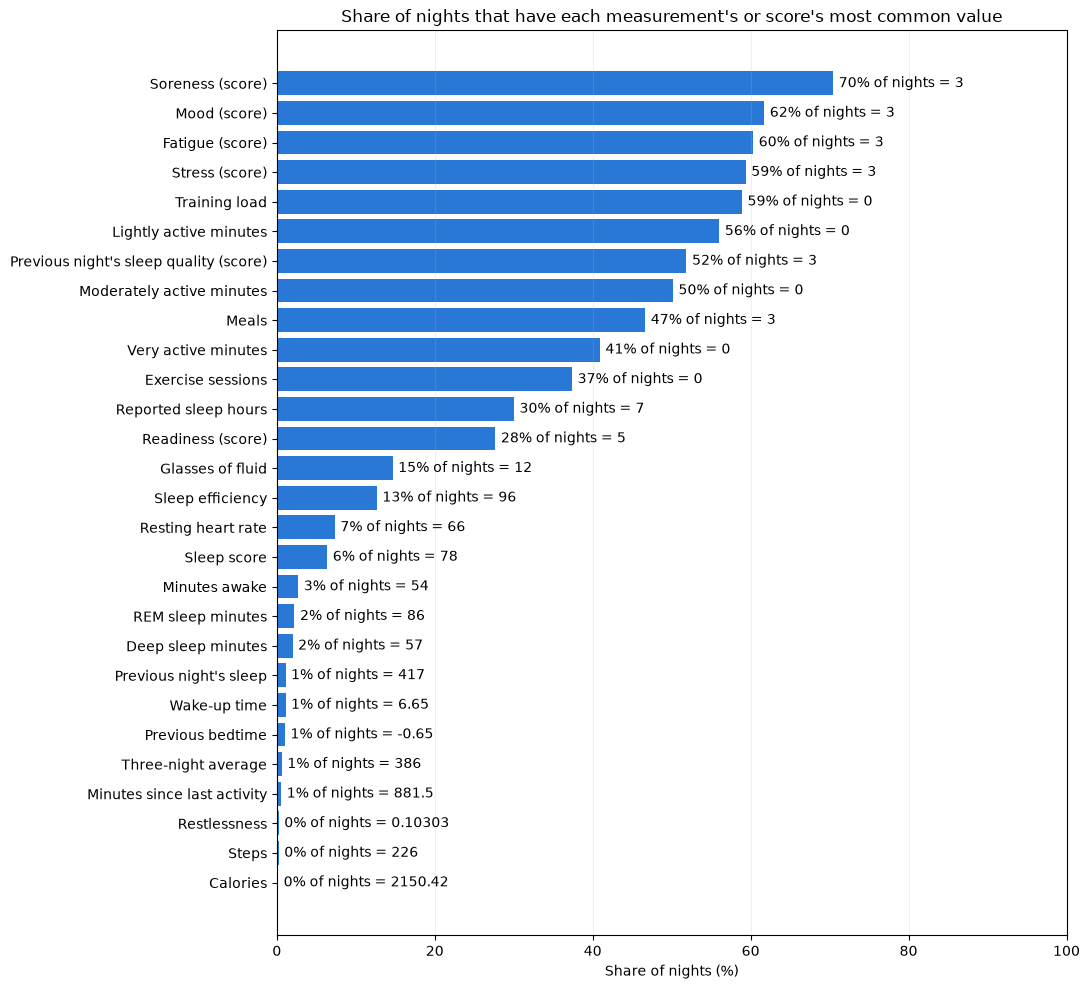

In [37]:
measurements = {
    "steps": "Steps",
    "calories": "Calories",
    "session_count": "Exercise sessions",
    "lightly_active_minutes": "Lightly active minutes",
    "moderately_active_minutes": "Moderately active minutes",
    "very_active_minutes": "Very active minutes",
    "min_since_last_activity": "Minutes since last activity",
    "training_load": "Training load",
    "previous_sleep_minutes": "Previous night's sleep",
    "avg_sleep_last_3_nights": "Three-night average",
    "previous_bedtime_hour": "Previous bedtime",
    "wake_up_hour": "Wake-up time",
    "previous_deep_minutes": "Deep sleep minutes",
    "previous_rem_minutes": "REM sleep minutes",
    "previous_awake_minutes": "Minutes awake",
    "previous_efficiency": "Sleep efficiency",
    "previous_sleep_score": "Sleep score",
    "previous_restlessness": "Restlessness",
    "resting_heart_rate": "Resting heart rate",
    "reported_sleep_hours": "Reported sleep hours",
    "meal_count": "Meals",
    "glasses_of_fluid": "Glasses of fluid",
    # The scores work the same way: a score that is the same on most nights says little.
    "fatigue": "Fatigue (score)",
    "stress": "Stress (score)",
    "mood": "Mood (score)",
    "previous_sleep_quality": "Previous night's sleep quality (score)",
    "soreness": "Soreness (score)",
    "readiness": "Readiness (score)",
}

most_common = pd.DataFrame([
    {
        "Measurement": name,
        "Most common value": nights[column].mode()[0],
        "Share of nights": nights[column].eq(nights[column].mode()[0]).sum() / nights[column].notna().sum(),
    }
    for column, name in measurements.items()
]).sort_values("Share of nights")

fig, ax = plt.subplots(figsize=(11, 10))
bars = ax.barh(most_common["Measurement"], most_common["Share of nights"] * 100, color="#2a78d6")
ax.bar_label(bars, labels=[f"{share:.0%} of nights = {value:g}" for share, value in
                           zip(most_common["Share of nights"], most_common["Most common value"])], padding=4)
ax.set_xlim(0, 100)
ax.set(title="Share of nights that have each measurement's or score's most common value",
       xlabel="Share of nights (%)", ylabel="")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

Variables that have a majority of the same answer might do very little for the model, so they won't improve R². Those results should be taken into account during the feature correlation stage. 

Everything is compared against the target, the following night's sleep, so I also want to see what it looks like on its own: which durations are normal, how spread out they are, and whether there are nights that look suspiciously short or long.

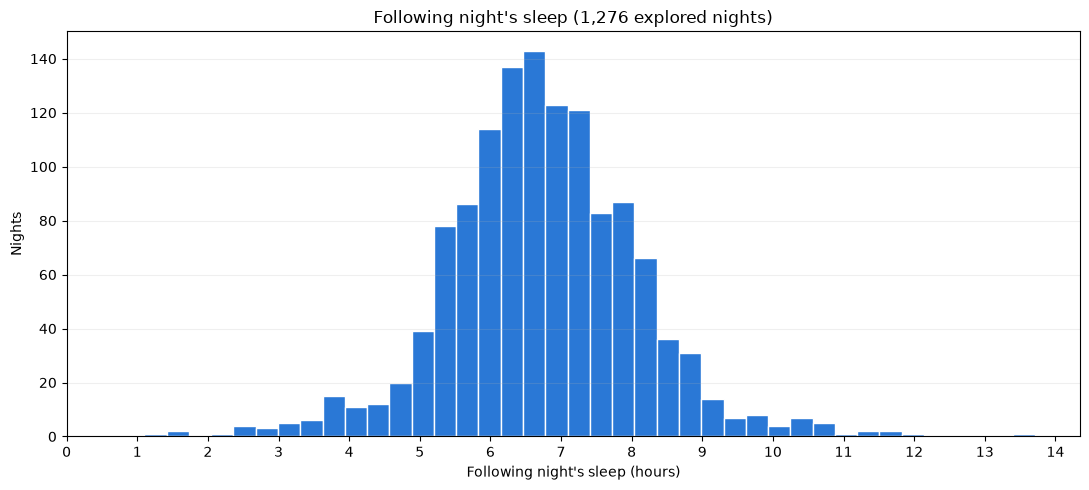

,count,mean,std,min,5%,25%,50%,75%,95%,max
Hours,1276.0,6.73,1.36,1.1,4.65,5.96,6.7,7.53,8.83,13.72


In [38]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(nights["next_sleep_hours"], bins=40, color="#2a78d6", edgecolor="white")
ax.set_xticks(range(0, 15))
ax.set(title=f"Following night's sleep ({len(nights):,} explored nights)",
       xlabel="Following night's sleep (hours)", ylabel="Nights")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

nights["next_sleep_hours"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2).to_frame("Hours").T

The spread seems reasonable, most nights have similar sleep. Most nights fall between 5-9h, with highest concentration between 6-7h per night

## Step 4: Categorical features

For the categories I want to know how many nights fall into each option: whether some options are so rare that a model cannot learn anything from them, and how balanced the yes/no answers are. Gender and A/B person were already shown in step 1, so here I look at the weekday, the last activity and the yes/no columns.

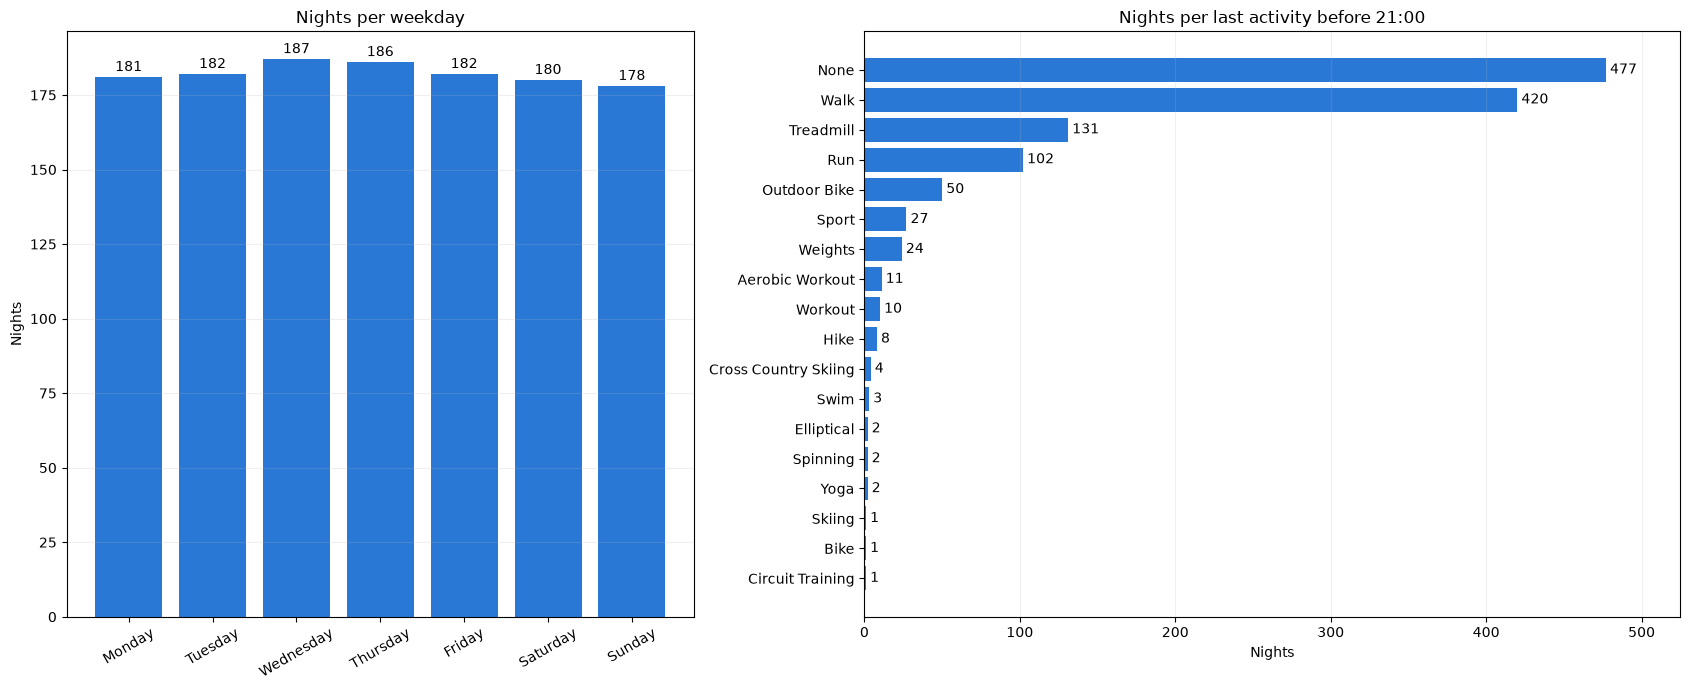

In [39]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_counts = nights["weekday"].value_counts().reindex(weekday_order)
activity_counts = nights["last_activity"].value_counts().sort_values()

fig, (left, right) = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1, 1.3]})
bars = left.bar(weekday_counts.index, weekday_counts.values, color="#2a78d6")
left.bar_label(bars, padding=2)
left.set(title="Nights per weekday", ylabel="Nights")
left.tick_params(axis="x", rotation=30)
left.grid(axis="y", alpha=0.2)

bars = right.barh(activity_counts.index, activity_counts.values, color="#2a78d6")
right.bar_label(bars, padding=3)
right.set(title="Nights per last activity before 21:00", xlabel="Nights")
right.margins(x=0.1)
right.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

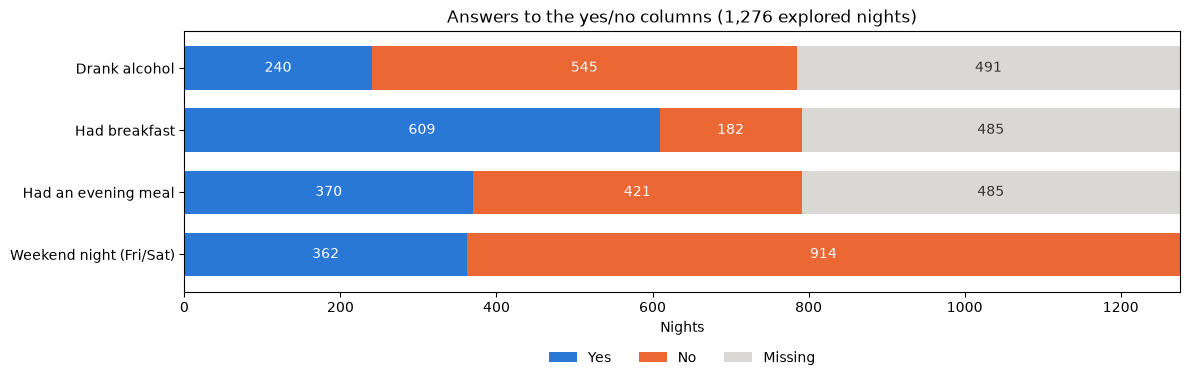

In [40]:
yes_no_columns = {
    "drank_alcohol": "Drank alcohol",
    "had_breakfast": "Had breakfast",
    "had_evening_meal": "Had an evening meal",
    "weekend_night": "Weekend night (Fri/Sat)",
}
answers = pd.DataFrame({
    name: nights[column].map({1: "Yes", 0: "No"}).fillna("Missing").value_counts()
    for column, name in yes_no_columns.items()
}).T.reindex(columns=["Yes", "No", "Missing"]).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(12, 4))
answers.iloc[::-1].plot.barh(stacked=True, color=["#2a78d6", "#eb6834", "#d9d8d4"], width=0.7, ax=ax)
for container, answer in zip(ax.containers, answers.columns):
    ax.bar_label(container, labels=[f"{v:.0f}" if v else "" for v in container.datavalues],
                 label_type="center", color="#333333" if answer == "Missing" else "white")
ax.set(title=f"Answers to the yes/no columns ({len(nights):,} explored nights)", xlabel="Nights", ylabel="")
ax.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

- Nights per last activity we already knew has a split like this, for it we used a numerical encoding during the first iteration. Perhaps I should consider merging them into an "other" category to reduce clutter and confusion into the model, but first I would need to see how specific activities correlate to the sleep duration.
- Alcohol nights seem to be about 1/3 of the present records, which can be a good feature.
- The different days from the weekday seem to have an even split, which is good as the model will likely be able to catch onto the patterns.
- More people noted that they had breakfast than an evening meal, which is interesting.
- Weekend night is about 1/3 of all nights, which is to be expected.

I am not sure yet how to encode the weekday of each night. The options I know of all have a downside:

- **A number (Monday = 0 … Sunday = 6):** one column, and tree models can split on any day. But for it won't really work well for linear regression, I might have to think whether I wish to keep that model at all.
- **Circular encoding (sine and cosine of the day):** two columns that place Sunday right next to Monday. But it describes a smooth wave over the week, so a single day that stands out cannot be captured well, it is harder to explain, and tree models have to combine two columns to find one day.
- **One-hot encoding (one yes/no column per day):** every day gets its own effect, but it adds seven columns for one piece of information, with only around 180 nights per day, so the model can more easily learn noise. It also loses the fact that the days follow each other.
- **A weekend yes/no (Friday or Saturday night):** one simple column, but it throws away any differences between the other days and between Friday and Saturday. It also has to follow the night and not the calendar date: the Friday row describes Friday night, before a free Saturday.

Since this might prove a bit of a challenge, I will ask my teacher for more guidance on which encoding fits best.

## Step 5: Outliers

I look at the measurements in the same groups as before, starting with the target and the sleep-related ones.

/var/folders/vr/zrzp8s2s59l7jbqqp1km6mj00000gn/T/ipykernel_48927/3870195705.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, widths=0.5, patch_artist=True,
/var/folders/vr/zrzp8s2s59l7jbqqp1km6mj00000gn/T/ipykernel_48927/3870195705.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, widths=0.5, patch_artist=True,
/var/folders/vr/zrzp8s2s59l7jbqqp1km6mj00000gn/T/ipykernel_48927/3870195705.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, widths=0.5, patch_artist=True,
/var/folders/vr/zrzp8s2s59l7jbqqp1km6mj00000gn/T/ipykernel_48927/3870195705.py:9: Matplotli

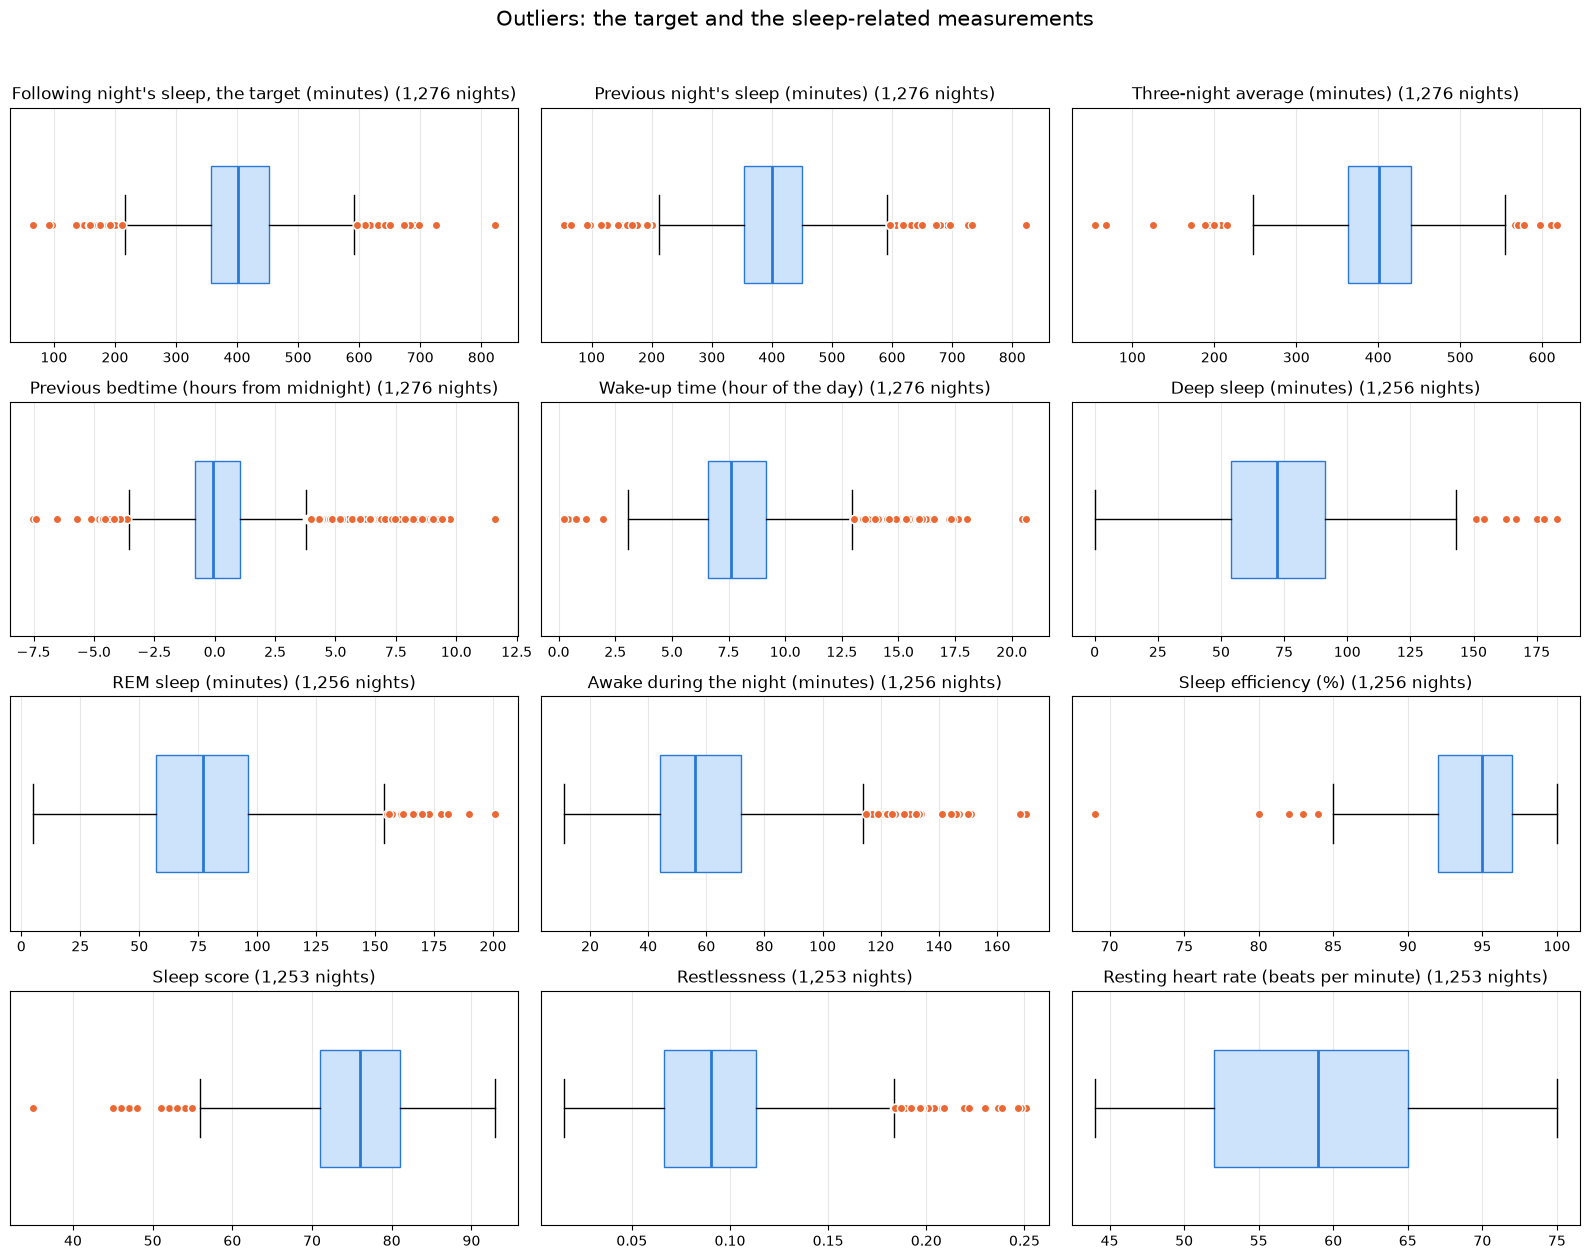

In [41]:
def plot_boxes(columns, group_title, drop_zeros=False):
    """One box plot per measurement, three per row, with every outlier drawn as a dot."""
    rows = int(np.ceil(len(columns) / 3))
    fig, axes = plt.subplots(rows, 3, figsize=(16, 3.2 * rows))
    for ax, (column, title) in zip(axes.flat, columns.items()):
        values = nights[column].dropna()
        if drop_zeros:
            values = values[values > 0]
        ax.boxplot(values, vert=False, widths=0.5, patch_artist=True,
                   boxprops={"facecolor": "#cde2fb", "edgecolor": "#2a78d6"},
                   medianprops={"color": "#2a78d6", "linewidth": 2},
                   flierprops={"marker": "o", "markerfacecolor": "#eb6834", "markeredgecolor": "white", "markersize": 6})
        ax.set_yticks([])
        ax.set_title(f"{title} ({len(values):,} nights)", fontsize=12)
        ax.grid(axis="x", alpha=0.3)
    for ax in axes.flat[len(columns):]:
        ax.set_visible(False)
    fig.suptitle(group_title, fontsize=15)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


plot_boxes({
    "next_sleep_minutes": "Following night's sleep, the target (minutes)",
    "previous_sleep_minutes": "Previous night's sleep (minutes)",
    "avg_sleep_last_3_nights": "Three-night average (minutes)",
    "previous_bedtime_hour": "Previous bedtime (hours from midnight)",
    "wake_up_hour": "Wake-up time (hour of the day)",
    "previous_deep_minutes": "Deep sleep (minutes)",
    "previous_rem_minutes": "REM sleep (minutes)",
    "previous_awake_minutes": "Awake during the night (minutes)",
    "previous_efficiency": "Sleep efficiency (%)",
    "previous_sleep_score": "Sleep score",
    "previous_restlessness": "Restlessness",
    "resting_heart_rate": "Resting heart rate (beats per minute)",
}, "Outliers: the target and the sleep-related measurements")

I can see that certain possible features tend to have quite a bit of outliers - Previous Bedtime, Weake up time, previous night sleep minutes, following night sleep duration, but before I dive in, I would like to explore the other groups first. Next will be the activity group.

/var/folders/vr/zrzp8s2s59l7jbqqp1km6mj00000gn/T/ipykernel_48927/3870195705.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, widths=0.5, patch_artist=True,
/var/folders/vr/zrzp8s2s59l7jbqqp1km6mj00000gn/T/ipykernel_48927/3870195705.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, widths=0.5, patch_artist=True,
/var/folders/vr/zrzp8s2s59l7jbqqp1km6mj00000gn/T/ipykernel_48927/3870195705.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, widths=0.5, patch_artist=True,
/var/folders/vr/zrzp8s2s59l7jbqqp1km6mj00000gn/T/ipykernel_48927/3870195705.py:9: Matplotli

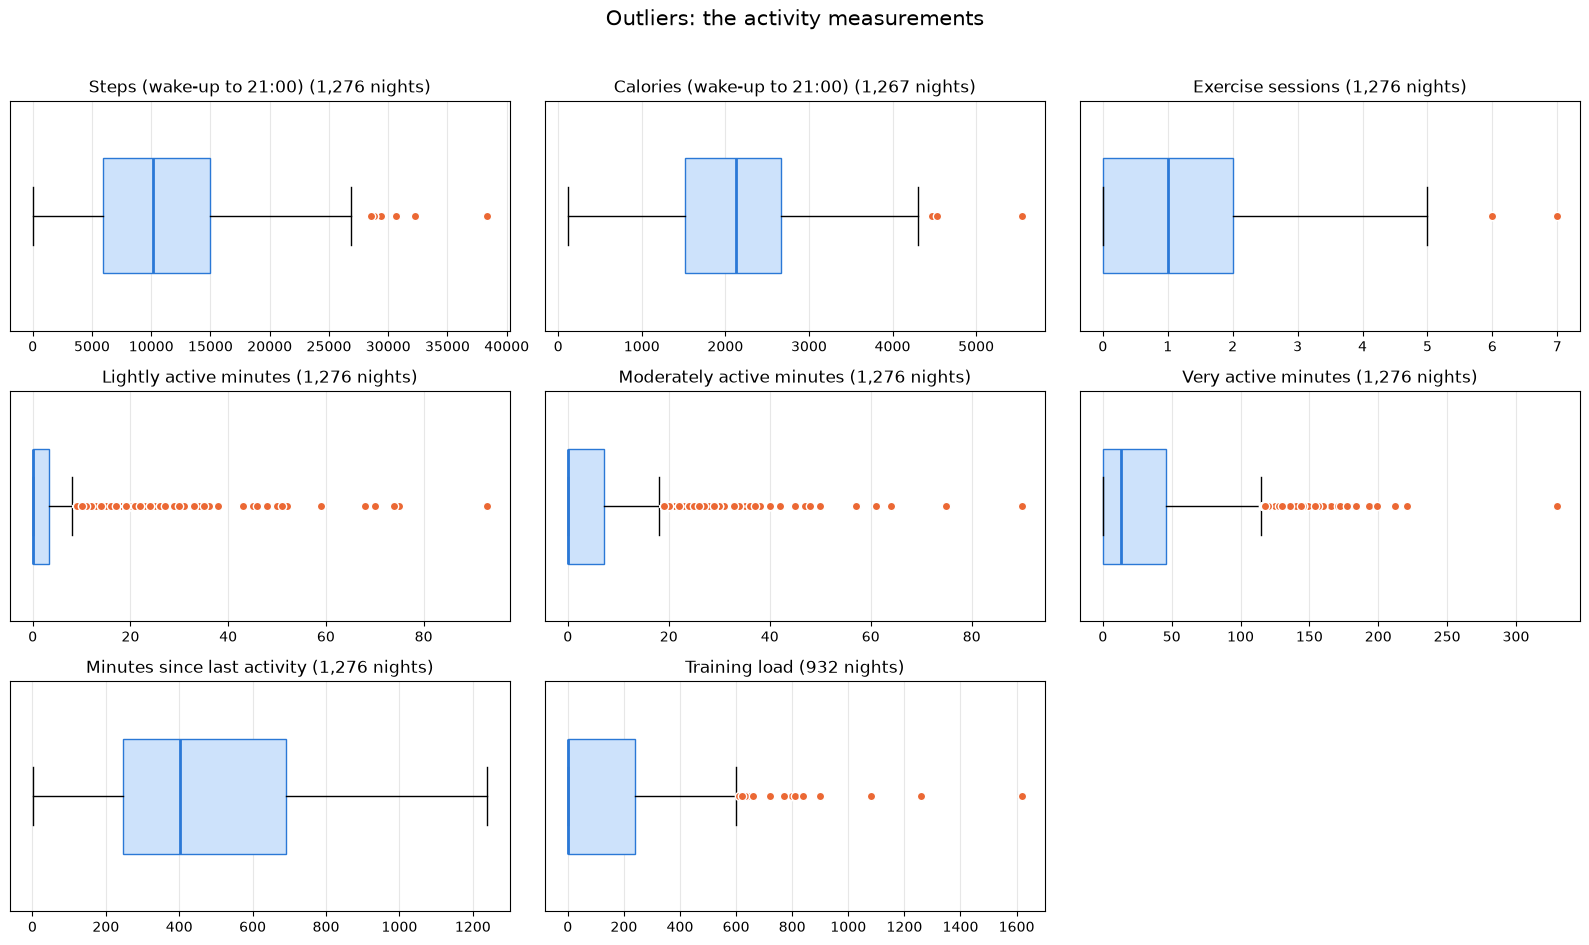

In [42]:
plot_boxes({
    "steps": "Steps (wake-up to 21:00)",
    "calories": "Calories (wake-up to 21:00)",
    "session_count": "Exercise sessions",
    "lightly_active_minutes": "Lightly active minutes",
    "moderately_active_minutes": "Moderately active minutes",
    "very_active_minutes": "Very active minutes",
    "min_since_last_activity": "Minutes since last activity",
    "training_load": "Training load",
}, "Outliers: the activity measurements")

The activity related fields are not getting calculated properly due to the majority of the entries being 0 values, this creates a bias, I will try to see them without the 0 entries.

/var/folders/vr/zrzp8s2s59l7jbqqp1km6mj00000gn/T/ipykernel_48927/3870195705.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, widths=0.5, patch_artist=True,
/var/folders/vr/zrzp8s2s59l7jbqqp1km6mj00000gn/T/ipykernel_48927/3870195705.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, widths=0.5, patch_artist=True,
/var/folders/vr/zrzp8s2s59l7jbqqp1km6mj00000gn/T/ipykernel_48927/3870195705.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, widths=0.5, patch_artist=True,
/var/folders/vr/zrzp8s2s59l7jbqqp1km6mj00000gn/T/ipykernel_48927/3870195705.py:9: Matplotli

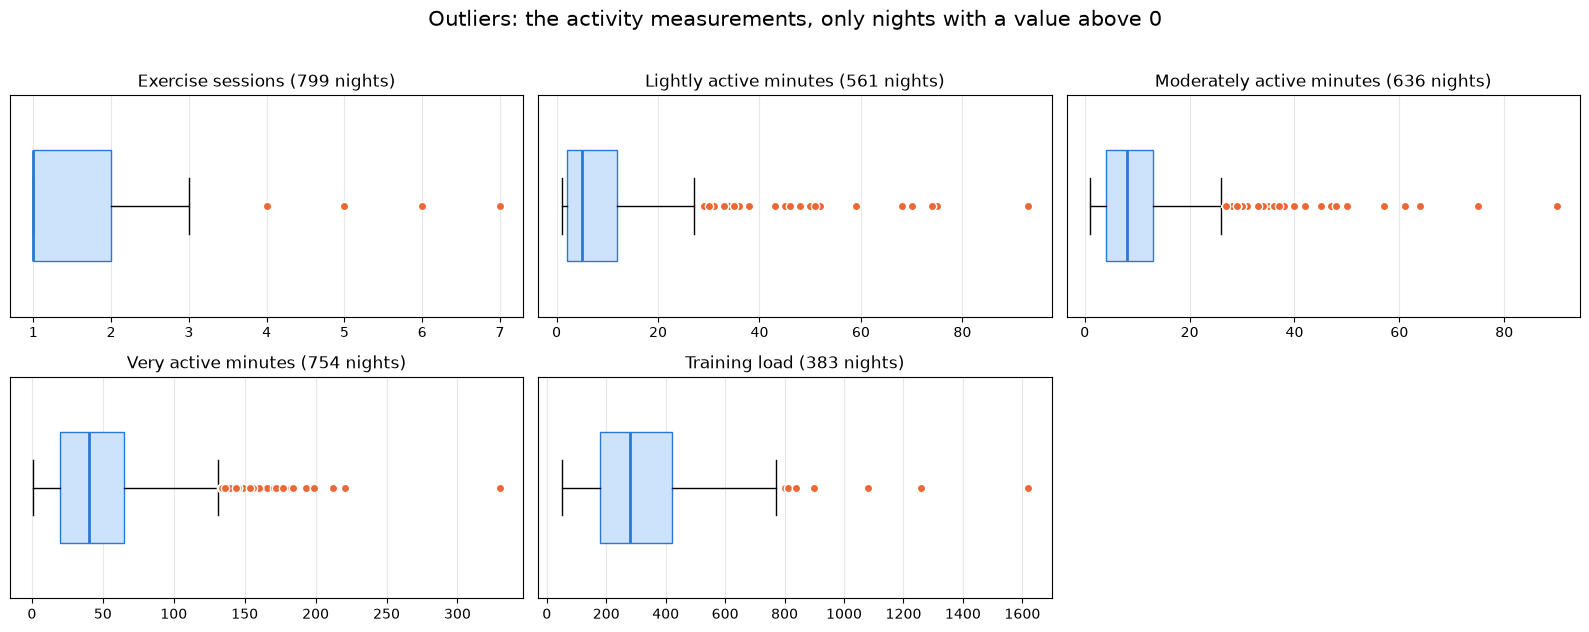

In [43]:
plot_boxes({
    "session_count": "Exercise sessions",
    "lightly_active_minutes": "Lightly active minutes",
    "moderately_active_minutes": "Moderately active minutes",
    "very_active_minutes": "Very active minutes",
    "training_load": "Training load",
}, "Outliers: the activity measurements, only nights with a value above 0", drop_zeros=True)

Even with 0 values excluded, entries seem to be mostly contained within the lower amount values.

/var/folders/vr/zrzp8s2s59l7jbqqp1km6mj00000gn/T/ipykernel_48927/3870195705.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, widths=0.5, patch_artist=True,
/var/folders/vr/zrzp8s2s59l7jbqqp1km6mj00000gn/T/ipykernel_48927/3870195705.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, widths=0.5, patch_artist=True,


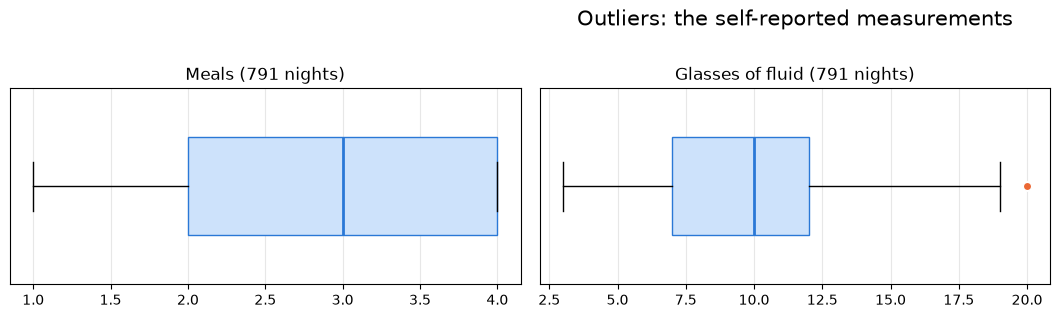

In [44]:
plot_boxes({
    "meal_count": "Meals",
    "glasses_of_fluid": "Glasses of fluid",
}, "Outliers: the self-reported measurements")

Its good to see that those don't have that many outliers, the other entries have been handled in the notebook already.

For the measurements with the most outliers, the sleep durations, bedtime and wake-up time, I want to know whose nights they are. If one participant's whole box lies outside the normal range, those nights are probably that person's normal routine; if the dots are scattered single nights of otherwise ordinary participants, they are more likely errors. The dashed lines show the normal range of all nights together, from the box plots above.

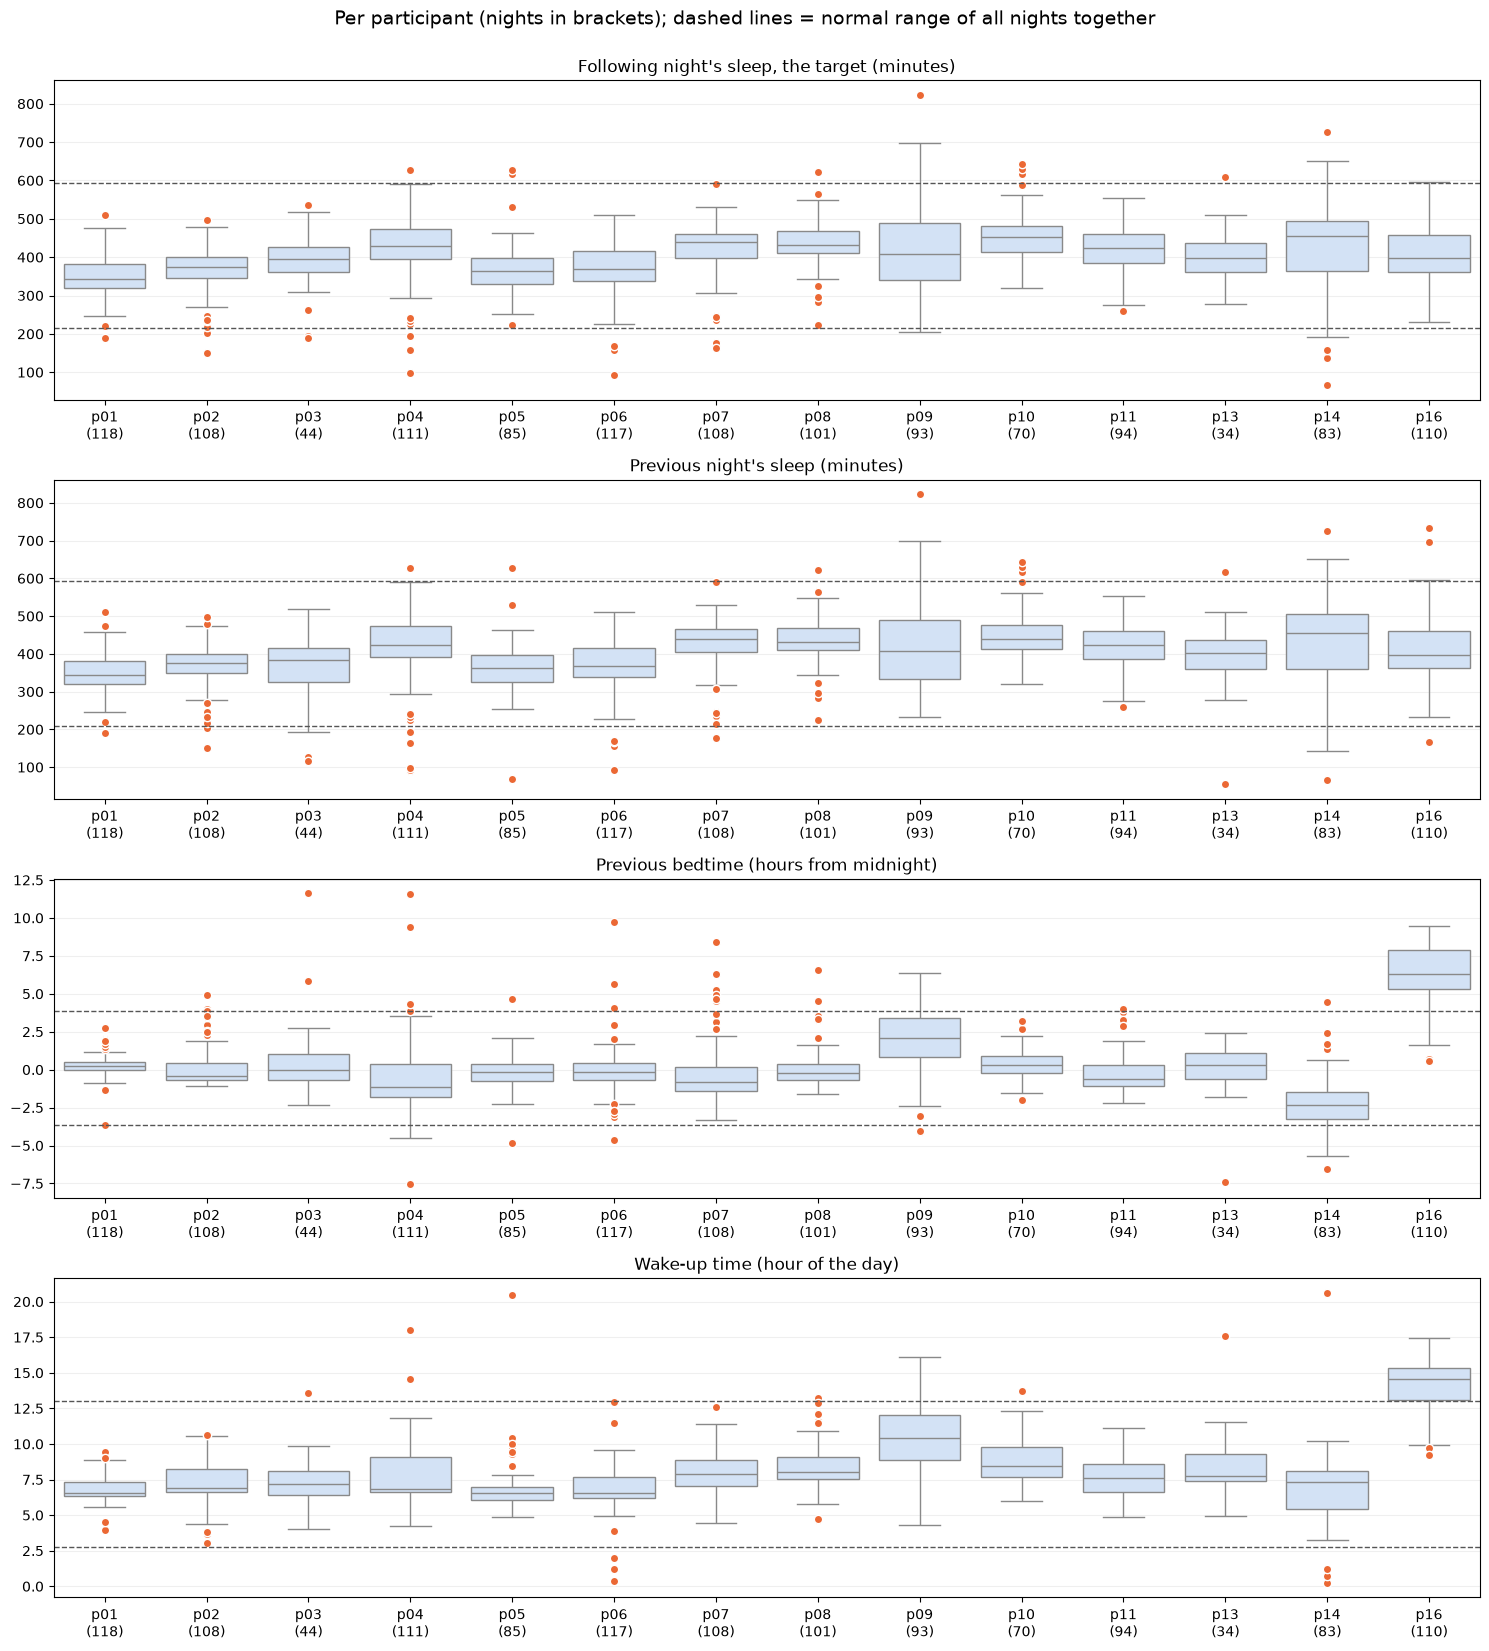

In [45]:
error_candidates = {
    "next_sleep_minutes": "Following night's sleep, the target (minutes)",
    "previous_sleep_minutes": "Previous night's sleep (minutes)",
    "previous_bedtime_hour": "Previous bedtime (hours from midnight)",
    "wake_up_hour": "Wake-up time (hour of the day)",
}
participants = sorted(nights["participant_id"].unique())

fig, axes = plt.subplots(len(error_candidates), 1, figsize=(15, 4.2 * len(error_candidates)))
for ax, (column, title) in zip(axes, error_candidates.items()):
    sns.boxplot(data=nights, x="participant_id", y=column, order=participants, color="#cde2fb", ax=ax,
                flierprops={"marker": "o", "markerfacecolor": "#eb6834", "markeredgecolor": "white", "markersize": 6})
    # The normal range of all nights together, as in the box plots above.
    q1, q3 = nights[column].quantile([0.25, 0.75])
    for limit in (q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)):
        if nights[column].min() <= limit <= nights[column].max():
            ax.axhline(limit, color="#555555", linestyle="--", linewidth=1)
    counts = nights.groupby("participant_id")[column].count().reindex(participants)
    ax.set_xticks(range(len(participants)), [f"{person}\n({n})" for person, n in counts.items()])
    ax.set(title=title, xlabel="", ylabel="")
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Per participant (nights in brackets); dashed lines = normal range of all nights together", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

Nights shorter than 3 hours (180 minutes) count as **hard outliers**: nobody really sleeps that little, so they are most likely recording errors, for example the watch being taken off during the night. Before deciding what to do with them, I check whether the participant's own morning report covers the same night. The morning report describes the night that just ended, so the previous night is matched with the same day's report, and the following night (the target) with the next day's report.

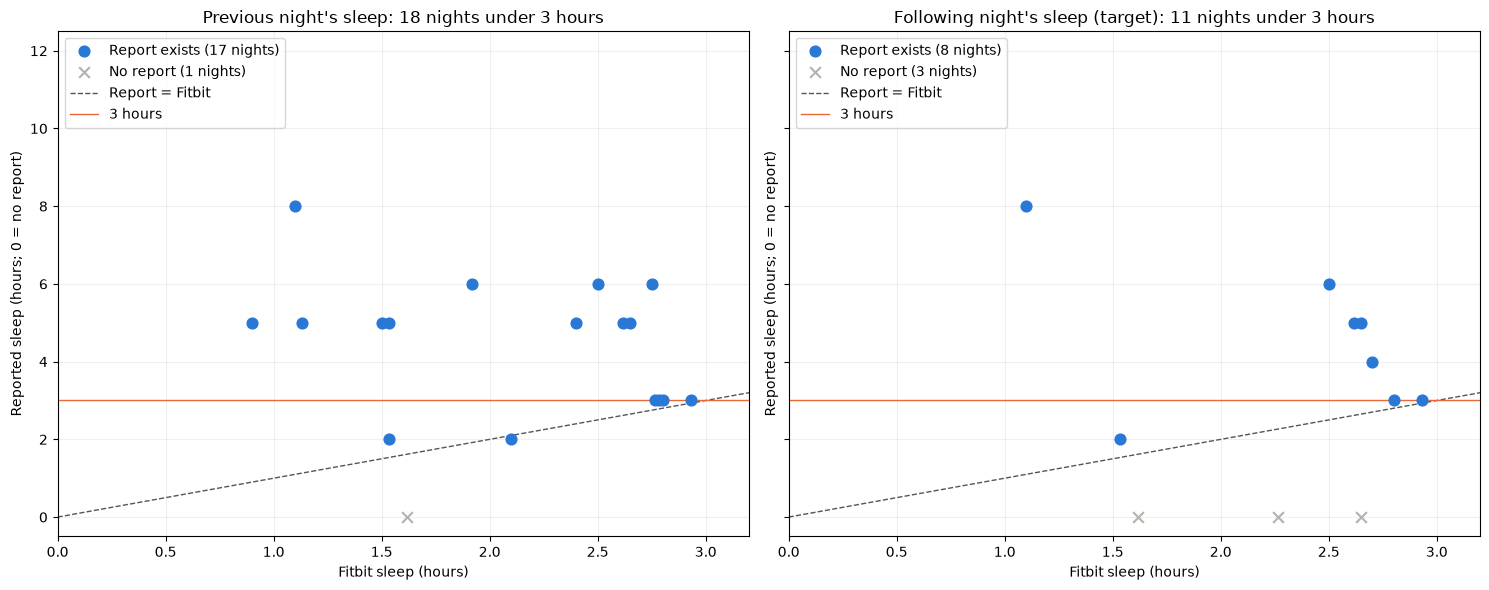

In [46]:
HARD_LIMIT = 180  # minutes

# The report that describes each row's following night is the next day's morning report.
report_lookup = candidates.set_index(["participant_id", "date"])["reported_sleep_hours"]
next_day_keys = pd.MultiIndex.from_arrays([nights["participant_id"], nights["date"] + pd.Timedelta(days=1)])
next_night_report = pd.Series(report_lookup.reindex(next_day_keys).to_numpy(), index=nights.index)

hard_checks = {
    "Previous night's sleep": (nights["previous_sleep_minutes"], nights["reported_sleep_hours"]),
    "Following night's sleep (target)": (nights["next_sleep_minutes"], next_night_report),
}

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for ax, (title, (fitbit_minutes, reported_hours)) in zip(axes, hard_checks.items()):
    hard = fitbit_minutes < HARD_LIMIT
    with_report = hard & reported_hours.notna()
    without_report = hard & reported_hours.isna()
    ax.scatter(fitbit_minutes[with_report] / 60, reported_hours[with_report], color="#2a78d6", s=60, zorder=3,
               label=f"Report exists ({with_report.sum()} nights)")
    ax.scatter(fitbit_minutes[without_report] / 60, [0] * without_report.sum(), color="#b4b2ac", marker="x", s=60,
               zorder=3, label=f"No report ({without_report.sum()} nights)")
    ax.plot([0, 12], [0, 12], color="#555555", linestyle="--", linewidth=1, label="Report = Fitbit")
    ax.axhline(3, color="#eb6834", linewidth=1, label="3 hours")
    ax.set(title=f"{title}: {hard.sum()} nights under 3 hours", xlabel="Fitbit sleep (hours)",
           ylabel="Reported sleep (hours; 0 = no report)", xlim=(0, 3.2), ylim=(-0.5, 12.5))
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

For the nights under 3 hours, the participant's own report will decide what happens:

- **The report says 3 hours or more:** the Fitbit most likely missed part of the night, for example because the watch was taken off. The Fitbit duration is replaced by the reported hours. Reports are whole hours from memory, so a replaced night becomes a flat number of hours (for example exactly 5 hours), which is less precise but much closer to the truth than the Fitbit value.
- **The report also says under 3 hours, or there is no report:** nothing proves the night was longer, and a night this short is not realistic, so the night is dropped.

This applies to both the previous night's sleep and the following night's sleep (the target). Like the decisions about the missing values, the rule is applied in feature engineering, to all nights including the test nights, and before the three-night average is calculated, so the average is built from the corrected nights. Here the nights are only explored, so they stay as they are.

### What I decide about the outliers
- **Nights under 3 hours** are hard outliers: if the participant's report says 3 hours or more, the reported hours replace the Fitbit value; otherwise the night is dropped. This is applied in feature engineering, to all nights.
- **Participants' normal routines are kept.** p16 goes to bed and wakes up much later than everyone else, and p14 goes to bed earlier. Their whole box lies outside the normal range, so these values are how they live, not errors, and the same people appear in the test nights.
- **Long nights, single late bedtimes and very active days are kept.** They are unusual but possible. For linear regression and the neural network, extreme values may be capped (for example at the 1st and 99th percentile of the training nights) in feature engineering; the tree models do not need this.
- **The odd wake-up times around 00:00–02:00 or 17:00–20:00** of otherwise regular participants might be recording problems. There are only a few, so they are kept and noted; if wake-up time turns out to matter for sleep, they are worth a second look.

## Step 6: Relationship with the target

Now I want to see which features actually go together with the following night's sleep. For every feature that is a number (the measurements, the scores and the yes/no answers), I calculate its correlation with the following night's sleep. I use the Spearman correlation, which only looks at whether higher values tend to go with longer or shorter sleep, so it also works for the 1–5 scores and is not pulled around by outliers.

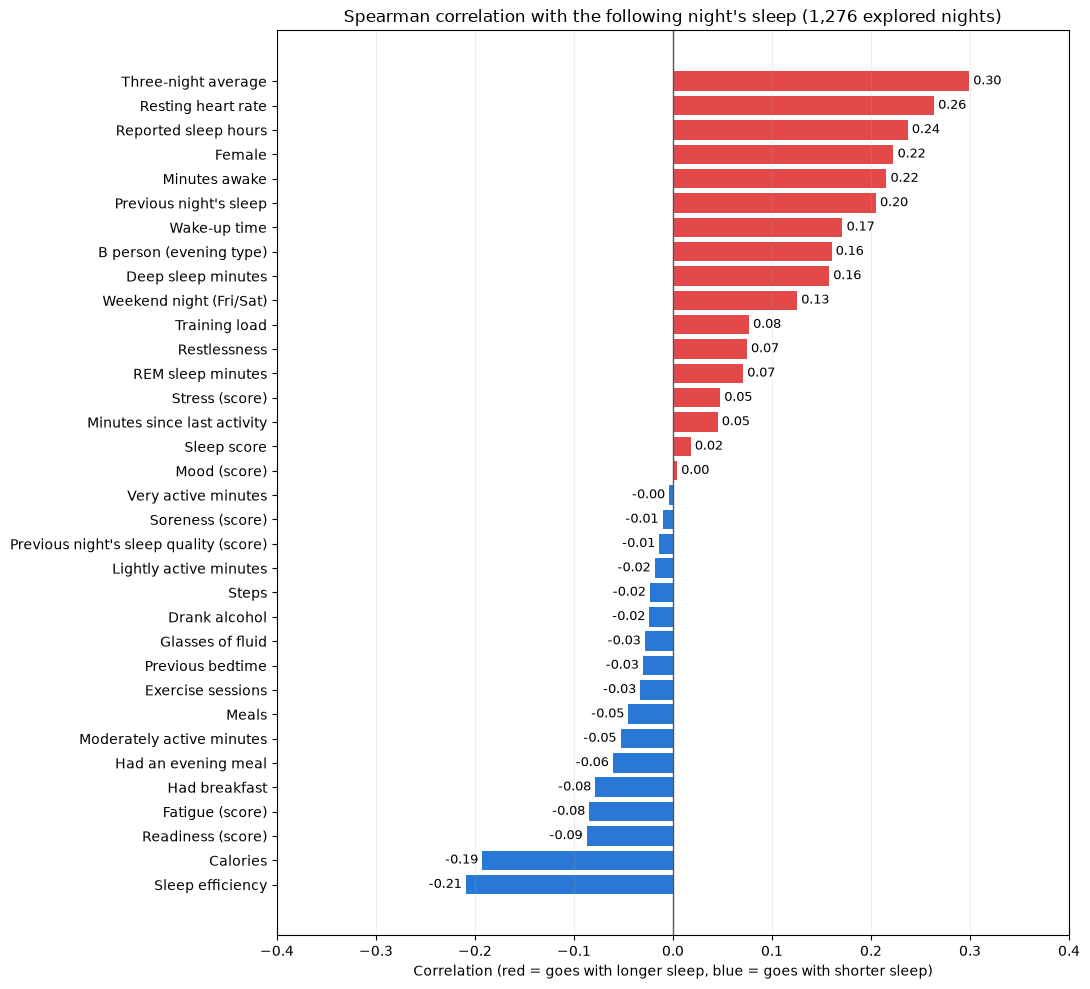

In [47]:
numeric_features = {
    column: name for column, name in measurements.items()
} | {
    "drank_alcohol": "Drank alcohol",
    "had_breakfast": "Had breakfast",
    "had_evening_meal": "Had an evening meal",
    "weekend_night": "Weekend night (Fri/Sat)",
    "is_female": "Female",
    "is_evening_type": "B person (evening type)",
}
nights["is_female"] = nights["gender"].eq("Female").astype(int)
nights["is_evening_type"] = nights["ab_type"].eq("B").astype(int)

sleep_correlation = pd.Series({
    name: nights[column].corr(nights["next_sleep_minutes"], method="spearman")
    for column, name in numeric_features.items()
}).sort_values()

fig, ax = plt.subplots(figsize=(11, 10))
colors = np.where(sleep_correlation > 0, "#e34948", "#2a78d6")
bars = ax.barh(sleep_correlation.index, sleep_correlation.values, color=colors)
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.axvline(0, color="#555555", linewidth=1)
ax.set_xlim(-0.4, 0.4)
ax.set(title=f"Spearman correlation with the following night's sleep ({len(nights):,} explored nights)",
       xlabel="Correlation (red = goes with longer sleep, blue = goes with shorter sleep)")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

Some results are as expected: women and evening types (B) tend to sleep longer, and so do people with a longer previous night, a longer three-night average and a later wake-up time. A higher resting heart rate also goes with longer sleep. "Minutes awake" is the time spent awake during the previous night, not during the day; together with the lower sleep efficiency, it means that people who spend longer in bed, awake parts included, also tend to sleep longer the next night. Most other features show almost no relation, and I was surprised that alcohol has hardly any (−0.02).

None of the correlations is strong; the highest is 0.30. Several of the strongest features describe the person rather than the night (gender, A/B type, resting heart rate, the three-night average), and there are only 3 women and 6 evening types, so part of these correlations may simply come from some people sleeping longer than others, but since we have no idea we will just stick with what we have.

The report columns only exist on some nights, so the correlations above are each calculated on a different set of nights. I want to see whether they change when I use only the nights that have both reports (the wellness report and the daily report).

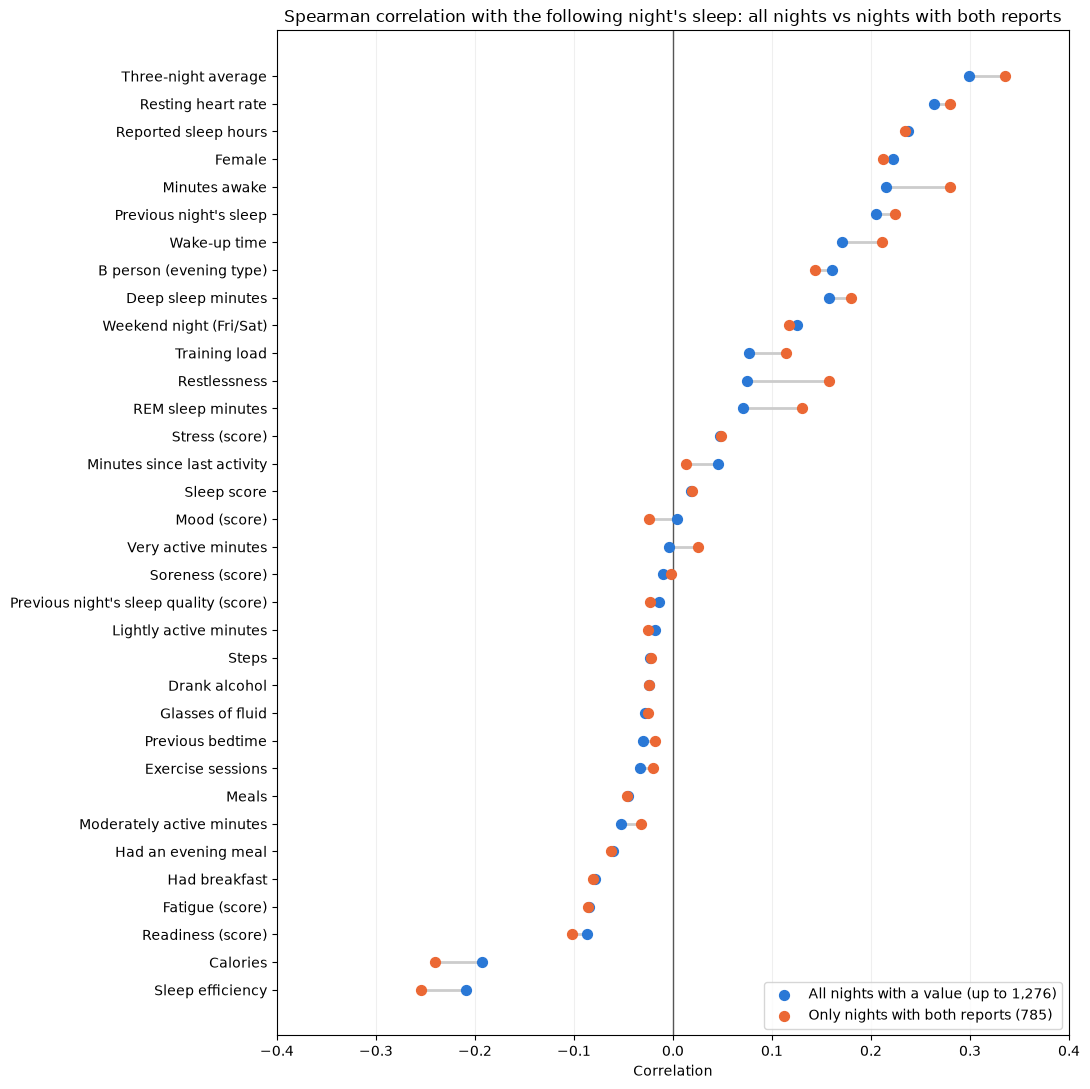

In [48]:
# Nights with both reports (wellness and daily report). Training load is not required here,
# because it is missing for everyone who barely used the training log.
report_columns = ["stress", "fatigue", "mood", "previous_sleep_quality", "soreness", "readiness",
                  "reported_sleep_hours", "meal_count", "had_breakfast", "had_evening_meal",
                  "glasses_of_fluid", "drank_alcohol"]
complete_nights = nights.dropna(subset=report_columns)
complete_correlation = pd.Series({
    name: complete_nights[column].corr(complete_nights["next_sleep_minutes"], method="spearman")
    for column, name in numeric_features.items()
})
both = pd.DataFrame({
    f"All nights with a value (up to {len(nights):,})": sleep_correlation,
    f"Only nights with both reports ({len(complete_nights):,})": complete_correlation,
}).loc[sleep_correlation.index]

positions = np.arange(len(both))
fig, ax = plt.subplots(figsize=(11, 11))
ax.hlines(positions, both.iloc[:, 0], both.iloc[:, 1], color="#cccccc", linewidth=2)
ax.scatter(both.iloc[:, 0], positions, color="#2a78d6", s=50, zorder=3, label=both.columns[0])
ax.scatter(both.iloc[:, 1], positions, color="#eb6834", s=50, zorder=3, label=both.columns[1])
ax.axvline(0, color="#555555", linewidth=1)
ax.set_yticks(positions, both.index)
ax.set_xlim(-0.4, 0.4)
ax.set(title="Spearman correlation with the following night's sleep: all nights vs nights with both reports",
       xlabel="Correlation")
ax.grid(axis="x", alpha=0.2)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

With only the nights that have both reports, most Fitbit correlations get a bit stronger (for example restlessness 0.07 → 0.16). This does not make the features better because we changed the data we have. The order of the features stays the same, so the conclusions do not depend on which nights are used.

The correlations so far mix different people: a feature can look related to sleep only because some people sleep longer than others. To check what happens within one person, I compare every night with that participant's own average, for both the feature and the sleep, and calculate the correlation again. Gender and A/B type are left out, because they never change for a person.

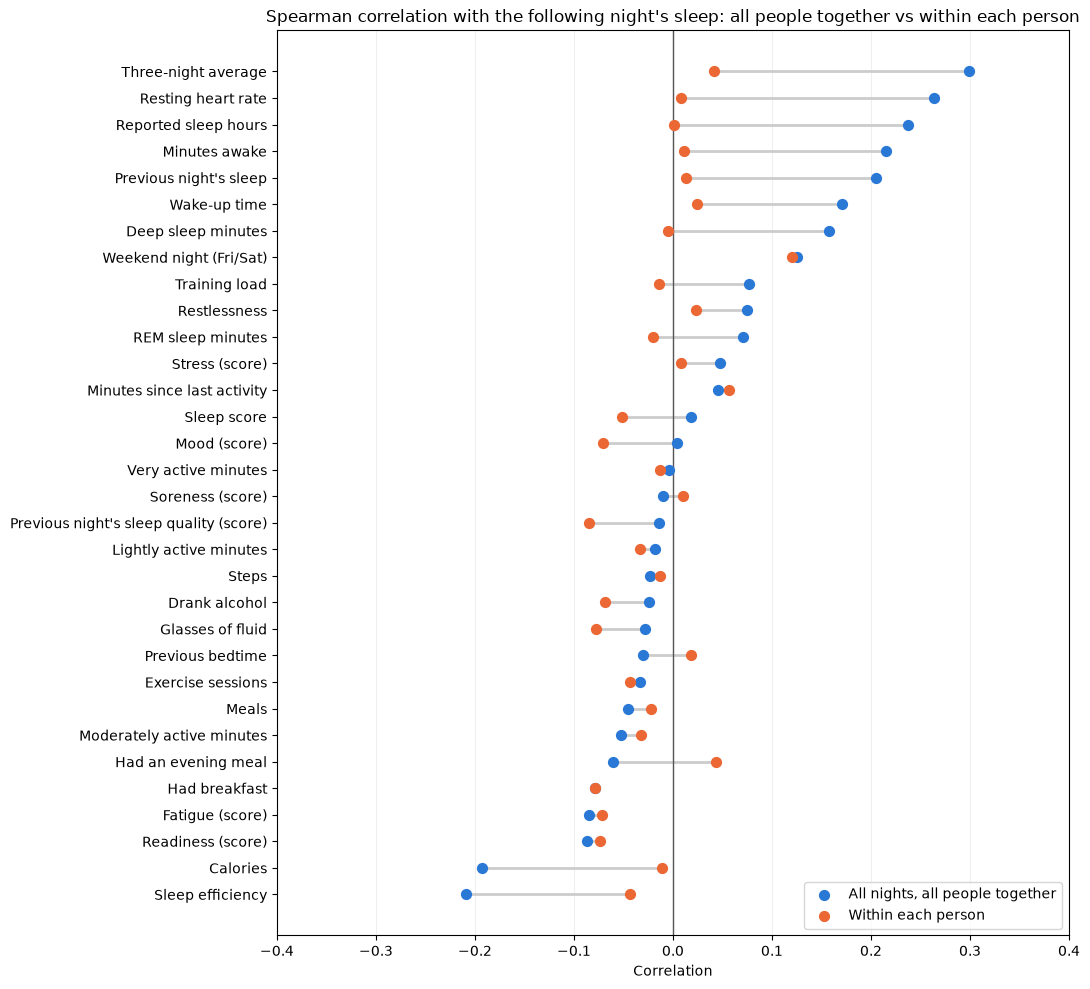

In [49]:
night_features = {column: name for column, name in numeric_features.items() if column not in ["is_female", "is_evening_type"]}

# Each value minus that participant's own average, for the features and for the sleep.
within = nights[list(night_features) + ["next_sleep_minutes"]].sub(
    nights.groupby("participant_id")[list(night_features) + ["next_sleep_minutes"]].transform("mean")
)
within_correlation = pd.Series({
    name: within[column].corr(within["next_sleep_minutes"], method="spearman")
    for column, name in night_features.items()
})
compare = pd.DataFrame({
    "All nights, all people together": sleep_correlation,
    "Within each person": within_correlation,
}).dropna().loc[lambda table: table.index.isin(within_correlation.index)]
compare = compare.loc[[name for name in sleep_correlation.index if name in compare.index]]

positions = np.arange(len(compare))
fig, ax = plt.subplots(figsize=(11, 10))
ax.hlines(positions, compare.iloc[:, 0], compare.iloc[:, 1], color="#cccccc", linewidth=2)
ax.scatter(compare.iloc[:, 0], positions, color="#2a78d6", s=50, zorder=3, label=compare.columns[0])
ax.scatter(compare.iloc[:, 1], positions, color="#eb6834", s=50, zorder=3, label=compare.columns[1])
ax.axvline(0, color="#555555", linewidth=1)
ax.set_yticks(positions, compare.index)
ax.set_xlim(-0.4, 0.4)
ax.set(title="Spearman correlation with the following night's sleep: all people together vs within each person",
       xlabel="Correlation")
ax.grid(axis="x", alpha=0.2)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Within each person, almost every correlation flattens towards 0. Most of the earlier correlations came from differences between people: some people simply sleep longer than others. Only the weekend night keeps its correlation (0.13 → 0.12), so it is the one feature that clearly goes with a longer night for the same person.

Different people have different habits, and different things affect their sleep. So giving the model a small profile of the person might actually be useful: their usual sleep (for example the three-night average), their gender and whether they are a morning or an evening type. The night-level features rarely say whether tonight will be longer or shorter than that person's usual.

A correlation can still miss an effect that only shows up on a few nights, though. For example, feeling much fresher than normal is rare, so even a large difference on those nights hardly moves the correlation over all nights.

So for the candidates that might matter on fewer nights, I also compare the following night's sleep in minutes: how much longer or shorter than that participant's usual sleep it is, for each group. The black lines show how certain each average is; when a line crosses 0, the difference may just be chance.

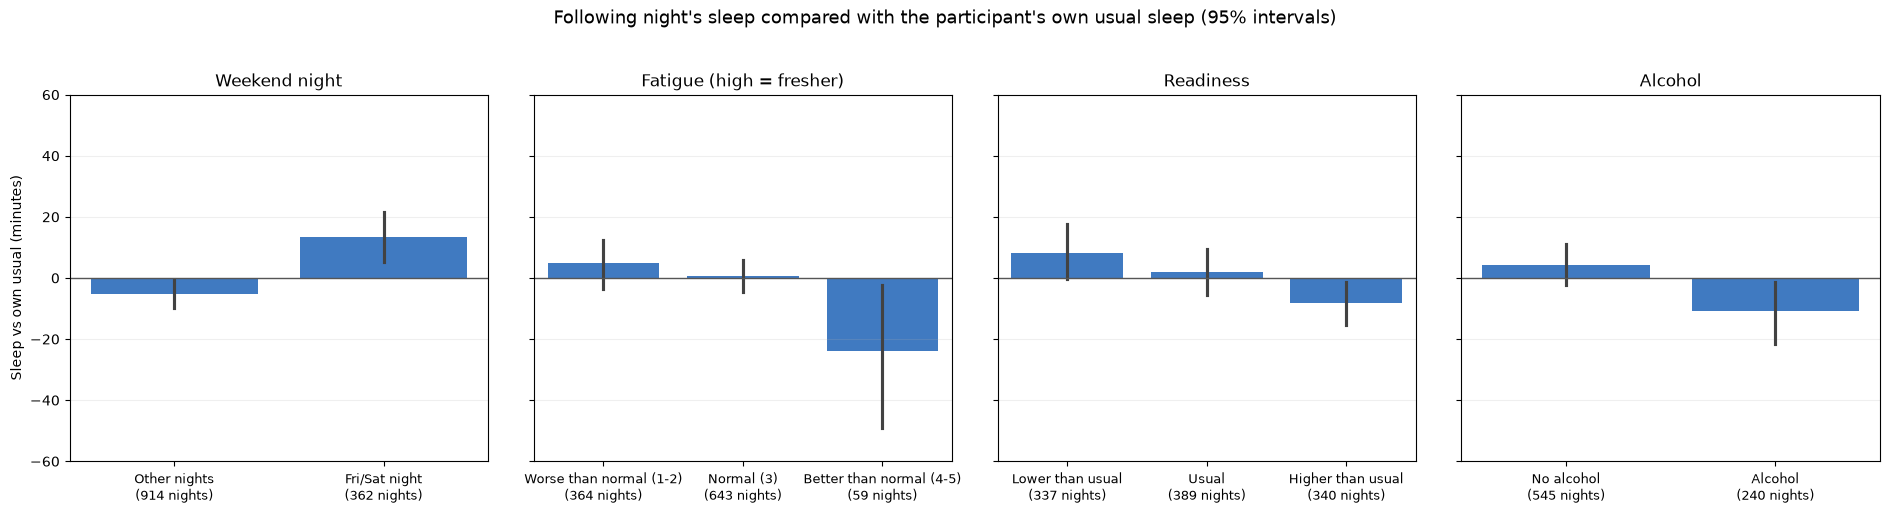

In [50]:
nights["sleep_vs_usual"] = (
    nights["next_sleep_minutes"] - nights.groupby("participant_id")["next_sleep_minutes"].transform("mean")
)


def plot_vs_usual(ax, groups, title, order):
    """Average difference from the participant's usual sleep per group, with the number of nights under each bar."""
    groups = groups.astype(str).where(groups.notna())
    counts = groups.value_counts()
    sns.barplot(x=groups, y=nights["sleep_vs_usual"], order=order, color="#2a78d6", ax=ax, errorbar=("ci", 95), seed=SEED)
    ax.set_xticks(range(len(order)), [f"{group}\n({counts.get(group, 0)} nights)" for group in order], fontsize=9)
    ax.axhline(0, color="#555555", linewidth=1)
    ax.set_ylim(-60, 60)
    ax.set(title=title, xlabel="", ylabel="Sleep vs own usual (minutes)")
    ax.grid(axis="y", alpha=0.2)


score_groups = ["Worse than normal (1-2)", "Normal (3)", "Better than normal (4-5)"]
readiness_rank = nights.groupby("participant_id")["readiness"].rank(pct=True)
usual_groups = ["Lower than usual", "Usual", "Higher than usual"]

fig, axes = plt.subplots(1, 4, figsize=(19, 5.2), sharey=True)
plot_vs_usual(axes[0], nights["weekend_night"].map({0: "Other nights", 1: "Fri/Sat night"}), "Weekend night",
              ["Other nights", "Fri/Sat night"])
plot_vs_usual(axes[1], pd.cut(nights["fatigue"], [0, 2, 3, 5], labels=score_groups), "Fatigue (high = fresher)",
              score_groups)
plot_vs_usual(axes[2], pd.cut(readiness_rank, [0, 1 / 3, 2 / 3, 1], labels=usual_groups), "Readiness", usual_groups)
plot_vs_usual(axes[3], nights["drank_alcohol"].map({0: "No alcohol", 1: "Alcohol"}), "Alcohol",
              ["No alcohol", "Alcohol"])
for ax in axes[1:]:
    ax.set_ylabel("")
fig.suptitle("Following night's sleep compared with the participant's own usual sleep (95% intervals)", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

- Friday and Saturday nights are about 13 minutes longer than the participant's usual sleep, and the other nights about 5 minutes shorter. The interval is clear of 0, so the weekend night is a good feature.
- Feeling fresher than normal (fatigue 4–5) comes before a night about 24 minutes shorter than usual, but only 59 nights are in that group and the interval is wide, so the effect is uncertain. Feeling worse than normal makes little difference. I will take it as a possible feature eitherway.
- Readiness points the same way: higher than usual comes before a night about 8 minutes shorter, lower than usual about 8 minutes longer. It is small, but it fits with fatigue: feeling rested comes before a shorter night.
- Nights after drinking alcohol are about 10 minutes shorter than usual. The effect is small, so it can still be included and tested.

Some candidates might carry the same information, for example the different measures of the previous night, or fatigue, readiness and sleep quality. Two features that repeat each other do not both need to be in the model, so I check how strongly the remaining candidates relate to each other. The following night's sleep is the last row, so each feature's link to the target can be read in the same picture.

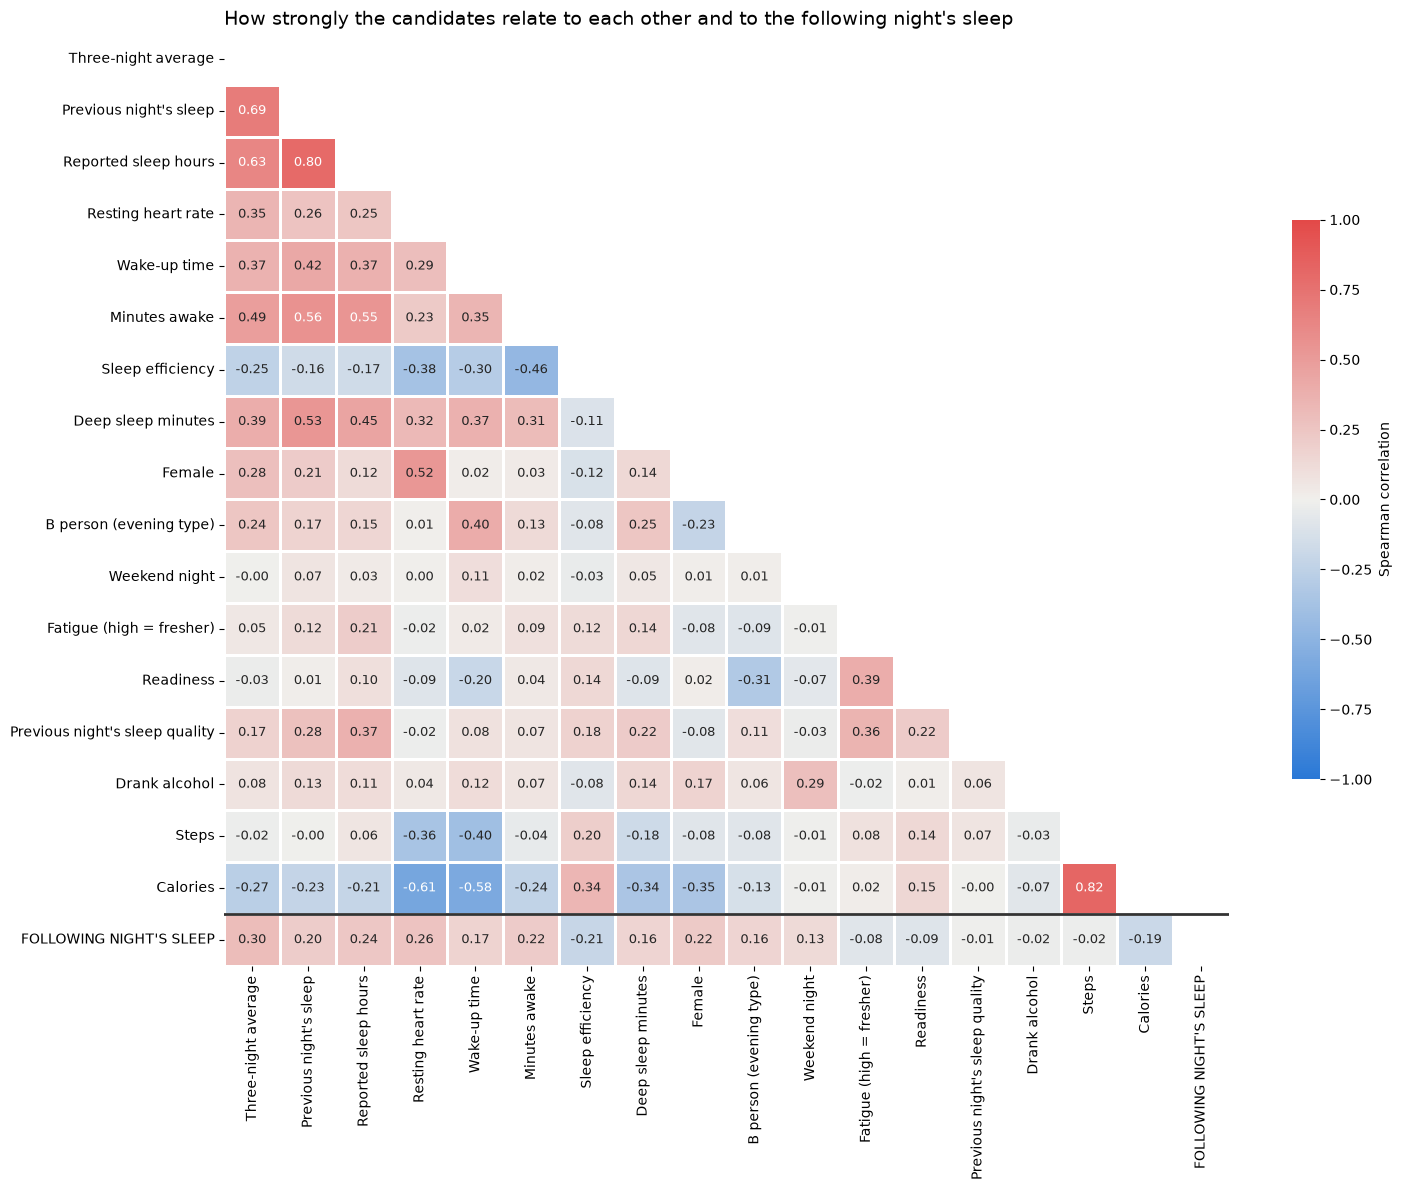

In [51]:
from matplotlib.colors import LinearSegmentedColormap

heatmap_features = {
    "avg_sleep_last_3_nights": "Three-night average",
    "previous_sleep_minutes": "Previous night's sleep",
    "reported_sleep_hours": "Reported sleep hours",
    "resting_heart_rate": "Resting heart rate",
    "wake_up_hour": "Wake-up time",
    "previous_awake_minutes": "Minutes awake",
    "previous_efficiency": "Sleep efficiency",
    "previous_deep_minutes": "Deep sleep minutes",
    "is_female": "Female",
    "is_evening_type": "B person (evening type)",
    "weekend_night": "Weekend night",
    "fatigue": "Fatigue (high = fresher)",
    "readiness": "Readiness",
    "previous_sleep_quality": "Previous night's sleep quality",
    "drank_alcohol": "Drank alcohol",
    "steps": "Steps",
    "calories": "Calories",
    "next_sleep_minutes": "FOLLOWING NIGHT'S SLEEP",
}
overlap = nights[list(heatmap_features)].corr(method="spearman").rename(index=heatmap_features, columns=heatmap_features)

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(
    overlap, mask=np.triu(np.ones_like(overlap, dtype=bool)), annot=True, fmt=".2f", annot_kws={"size": 9},
    cmap=LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"]),
    vmin=-1, vmax=1, center=0, linewidths=1, linecolor="white", cbar_kws={"label": "Spearman correlation", "shrink": 0.6}, ax=ax,
)
ax.axhline(len(heatmap_features) - 1, color="#333333", linewidth=2)
ax.set_title("How strongly the candidates relate to each other and to the following night's sleep", loc="left", fontsize=14)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

From the heatmap I drop:
- **Alcohol, for now:** almost no link with the following night's sleep (−0.02), only about 10 minutes in the comparison above, and missing on 43% of the nights, so filling the gaps would blur the little effect there is. Because alcohol is known to disturb sleep, it gets one test in feature selection: if adding it improves the validation error, it goes back in.
- **Reported sleep hours:** almost the same as the previous night's sleep from the Fitbit (0.80).
- **The previous night's sleep:** the three-night average is partly built from it (0.69), so it mostly repeats the average and only adds noise. The average has the stronger link with the following night's sleep (0.30 against 0.20), so I keep the average instead.
- **Steps:** almost no link with sleep (−0.02), and it largely repeats calories (0.82).
- **Previous night's sleep quality:** almost no link with sleep (−0.01), and it partly repeats fatigue (0.36).

I keep:
- **The details of the last night** (minutes awake, sleep efficiency, deep sleep). They overlap with the three-night average, but they describe different things: how restless and how deep the last night was, while the average only says how long the last nights were on average. They help describe the person.
- **The timing** (wake-up time and A/B person) and **the profile** (gender and resting heart rate). They partly overlap (evening types wake up later; women have a higher resting heart rate), but they describe who the person is and how they live.
- **Calories**, as the only activity measure left. It partly reflects how long the day was and who the person is (−0.58 with the wake-up time, −0.61 with the resting heart rate), so whether it adds anything is decided in feature selection.
- **Fatigue and readiness** are related (0.39) but not the same, and both showed small differences in minutes, so whether they help is decided in feature selection.

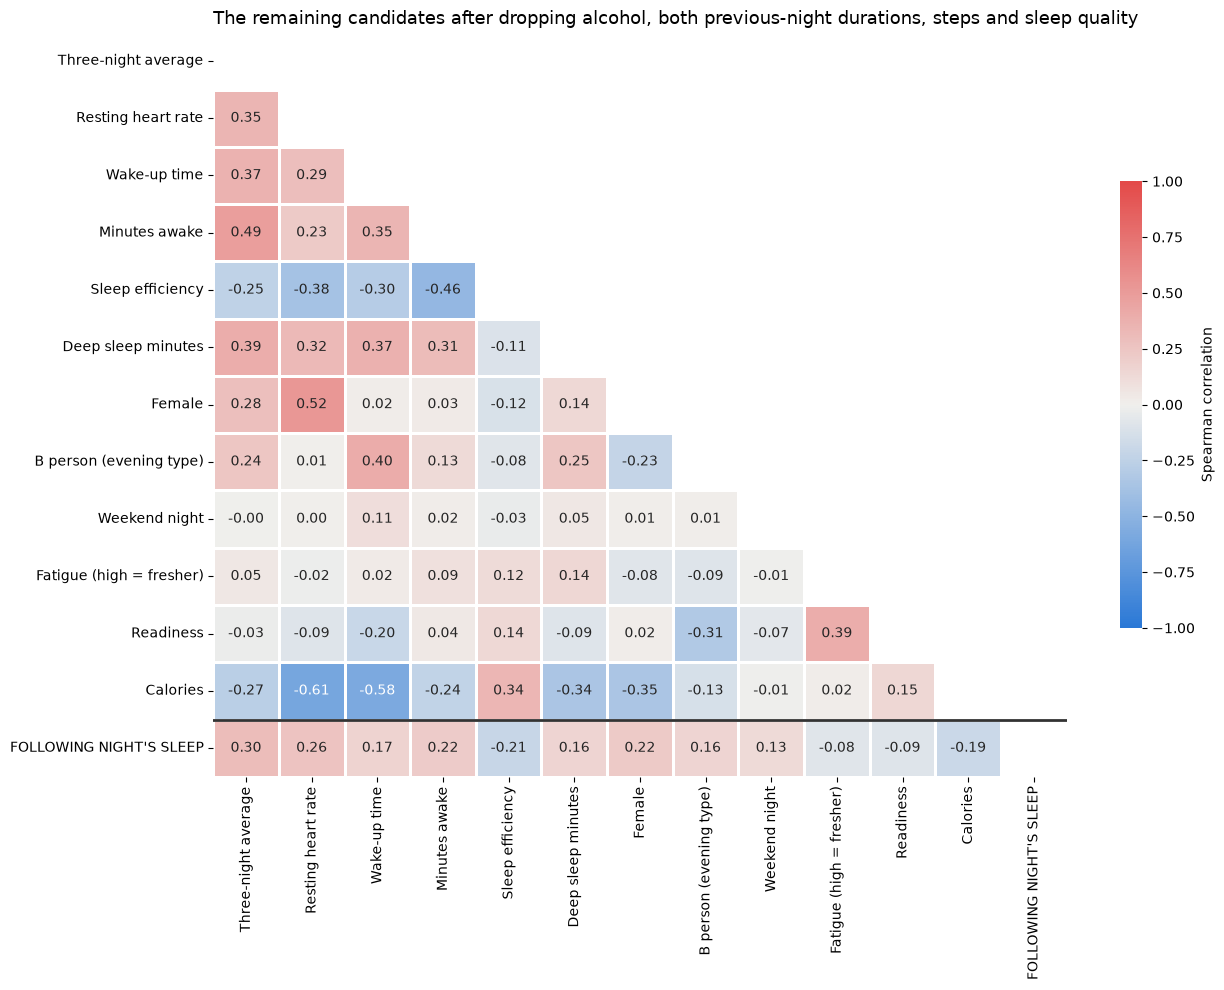

In [52]:
dropped = ["drank_alcohol", "reported_sleep_hours", "previous_sleep_minutes", "steps", "previous_sleep_quality"]
remaining = {column: name for column, name in heatmap_features.items() if column not in dropped}
overlap = nights[list(remaining)].corr(method="spearman").rename(index=remaining, columns=remaining)

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    overlap, mask=np.triu(np.ones_like(overlap, dtype=bool)), annot=True, fmt=".2f", annot_kws={"size": 10},
    cmap=LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"]),
    vmin=-1, vmax=1, center=0, linewidths=1, linecolor="white", cbar_kws={"label": "Spearman correlation", "shrink": 0.6}, ax=ax,
)
ax.axhline(len(remaining) - 1, color="#333333", linewidth=2)
ax.set_title("The remaining candidates after dropping alcohol, both previous-night durations, steps and sleep quality",
             loc="left", fontsize=13)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

## Conclusion

The EDA shows that most of what can be predicted about the following night's sleep is **who the person is**: their usual sleep, their body and their routine. Within one person, almost nothing predicts whether tonight will be longer or shorter than usual, except the weekend night. This also explains the low R² of the first iteration, and it means a good model will mostly learn "this person's usual sleep, plus a weekend bump".

### Features going into feature selection

| Role | Features |
| --- | --- |
| Usual sleep | three-night average |
| Last night's details | minutes awake, sleep efficiency, deep sleep minutes |
| Profile and timing | resting heart rate, gender, A/B person, wake-up time |
| Calendar | weekend night / weekday (encoding still to decide) |
| How they feel | fatigue, readiness |
| Activity | calories |

### Dropped

| Feature | Reason |
| --- | --- |
| Previous night's sleep, reported sleep hours | Repeat the three-night average (0.69 and 0.80 overlap) |
| Steps | No link with sleep, and repeats calories (0.82) |
| Previous night's sleep quality | No link with sleep, and partly repeats fatigue |
| Alcohol | Almost no link and missing on 43% of nights; tested once in feature selection |
| Active minutes, exercise sessions, training load, minutes since last activity | Mostly 0 (step 3) and no link with sleep in any check |
| Stress, mood, soreness, meals, glasses of fluid, breakfast, evening meal | No link with sleep in any check |
| REM minutes, restlessness, sleep score, previous bedtime | Weak links that disappear within each person |
| Last activity type | Not compared with sleep directly; the activity amounts showed no link, so it is left out, and can be tested in feature selection |

### What happens next
- **Feature engineering** applies the decisions: p15 is dropped, nights under 3 hours are replaced by the participant's report or dropped, missing report values are filled with the participant's own earlier average plus a "report missing" column, and extreme values may be capped for linear regression and the neural network.
- **Feature selection** compares feature sets on the validation nights, from the smallest to the largest: the three-night average and the weekend night only; then adding the profile and timing; then last night's details; then how they feel and calories; and finally alcohol once. Every set is compared against the seven-night-average baseline from the first iteration. The weekday encodings (a number, sine and cosine, one-hot, or a weekend yes/no) are compared the same way, and I will ask my teacher for guidance on them.